In [349]:
# Import packages for data manipulation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import packages for data visualization
import matplotlib.pyplot as plt

# This lets us see all of the columns, preventing Juptyer from redacting them.
pd.set_option('display.max_columns', None)

# Import packages for data modeling
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.metrics import accuracy_score, precision_score, recall_score,\
f1_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# This is the function that helps plot feature importance
from xgboost import plot_importance

# This module lets us save our models once we fit them.
import pickle

import folium
from folium.plugins import HeatMap

In [350]:
df_order = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_orders_dataset.csv") #main df 

df_cus = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_customers_dataset.csv") #join
df_item = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_order_items_dataset.csv") #join
df_product = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_products_dataset.csv") #join
df_geo = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_geolocation_dataset.csv")  
df_sell= pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_sellers_dataset.csv") 

df_cat_name = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/product_category_name_translation.csv") #optional
df_pay = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_order_payments_dataset.csv") #optional

df_rev = pd.read_csv("C:/Users/Ed/Desktop/DA/Brazilian E-Commerce/olist_order_reviews_dataset.csv") #optional

# Data wrangling (drop na / join)

In [351]:
df_order=df_order.dropna()

In [352]:
len(df_order)

96461

In [353]:
df_order.duplicated().sum()

np.int64(0)

In [354]:
df_order.head(1)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00


In [355]:
df_geo=df_geo.dropna()

In [356]:
len(df_geo)

1000163

In [357]:
df_geo.head(1)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP


In [358]:
df_geo.duplicated().sum() # it show many deuplicated records

np.int64(261831)

In [359]:
df_geo[df_geo.duplicated()]

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
15,1046,-23.546081,-46.644820,sao paulo,SP
44,1046,-23.546081,-46.644820,sao paulo,SP
65,1046,-23.546081,-46.644820,sao paulo,SP
66,1009,-23.546935,-46.636588,sao paulo,SP
67,1046,-23.546081,-46.644820,sao paulo,SP
...,...,...,...,...,...
1000153,99970,-28.343273,-51.873734,ciriaco,RS
1000154,99950,-28.070493,-52.011342,tapejara,RS
1000159,99900,-27.877125,-52.224882,getulio vargas,RS
1000160,99950,-28.071855,-52.014716,tapejara,RS


In [360]:
df_geo=df_geo.drop_duplicates(subset='geolocation_zip_code_prefix', keep='first')

In [361]:
df_geo.duplicated().sum()

np.int64(0)

In [362]:
df_geo=df_geo.drop(columns=['geolocation_city','geolocation_state'])

In [363]:
df_geo.head(1)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,1037,-23.545621,-46.639292


In [364]:
len(df_geo)

19015

In [365]:
df_cus=df_cus.dropna()

In [366]:
len(df_cus) 

99441

In [367]:
df_cus.duplicated().sum()

np.int64(0)

In [368]:
df_cus.head(1)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP


In [369]:
df_full=df_order.merge(df_cus , on='customer_id',how='inner')

In [370]:
df_full.head(1)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP


In [371]:
df_full.isna().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
dtype: int64

In [372]:
len(df_full)

96461

In [373]:
df_geo=df_geo.rename(columns={'geolocation_zip_code_prefix':'customer_zip_code_prefix',
                             'geolocation_lat':'cus_geolocation_lat',
                             'geolocation_lng':'cus_geolocation_lng'})

In [374]:
df_geo.head(1)

,customer_zip_code_prefix,cus_geolocation_lat,cus_geolocation_lng
0,1037,-23.545621,-46.639292


In [375]:
df_full=df_full.merge(df_geo , on='customer_zip_code_prefix',how='inner') #use inner to filter records without location info

In [376]:
df_full.head(1)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,-23.574809,-46.587471


In [377]:
df_full.isna().sum()

order_id                         0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
cus_geolocation_lat              0
cus_geolocation_lng              0
dtype: int64

In [378]:
len(df_full) #not much loss info

96197

In [379]:
df_full["order_id"].is_unique

True

**Merge item tb with full_df**

In [380]:
len(df_item)

112650

In [381]:
df_item.duplicated().sum()

np.int64(0)

In [382]:
df_item.isna().sum()

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [383]:
df_full=df_item.merge(df_full, on='order_id',how='inner') #keep all the item info in each order 

In [384]:
len(df_full)

109892

In [385]:
df_full.isna().sum()

order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
cus_geolocation_lat              0
cus_geolocation_lng              0
dtype: int64

In [386]:
df_sell.head(1)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP


In [387]:
df_sell.duplicated().sum()

np.int64(0)

In [388]:
df_sell.isna().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [389]:
df_full=df_full.merge(df_sell,on='seller_id')

In [390]:
len(df_full)

109892

In [391]:
df_full.head(1)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.758076,-41.312633,27277,volta redonda,SP


In [392]:
df_geo.head(1)

,customer_zip_code_prefix,cus_geolocation_lat,cus_geolocation_lng
0,1037,-23.545621,-46.639292


In [393]:
df_geo=df_geo.rename(columns={'customer_zip_code_prefix':'seller_zip_code_prefix',
                              'cus_geolocation_lat':'S_geolocation_lat',
                              'cus_geolocation_lng':'S_geolocation_lng'})

In [394]:
df_geo.head(1)

,seller_zip_code_prefix,S_geolocation_lat,S_geolocation_lng
0,1037,-23.545621,-46.639292


In [395]:
df_full=df_full.merge(df_geo,on='seller_zip_code_prefix',how='inner')

In [396]:
len(df_full)

109644

In [397]:
df_full.isna().sum()

order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
cus_geolocation_lat              0
cus_geolocation_lng              0
seller_zip_code_prefix           0
seller_city                      0
seller_state                     0
S_geolocation_lat                0
S_geolocation_lng                0
dtype: int64

In [398]:
df_full.head(1)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29 00:00:00,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.758076,-41.312633,27277,volta redonda,SP,-22.498183,-44.123614


**merge product table**

In [399]:
len(df_product)

32951

In [400]:
df_product.isna().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [401]:
df_product[df_product['product_width_cm'].isna()] 

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [402]:
df_product=df_product.drop(index=[18851,8578])

In [403]:
df_product.isna().sum()

product_id                      0
product_category_name         609
product_name_lenght           609
product_description_lenght    609
product_photos_qty            609
product_weight_g                0
product_length_cm               0
product_height_cm               0
product_width_cm                0
dtype: int64

In [404]:
df_product=df_product.drop(columns=['product_name_lenght','product_description_lenght','product_photos_qty'])

In [405]:
df_product['product_category_name'] = df_product['product_category_name'].fillna('Other')

In [406]:
df_product.isna().sum()

product_id               0
product_category_name    0
product_weight_g         0
product_length_cm        0
product_height_cm        0
product_width_cm         0
dtype: int64

In [407]:
df_full=df_full.merge(df_product,on='product_id',how='inner')

In [408]:
len(df_full)

109626

In [409]:
df_full.isna().sum()

order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
cus_geolocation_lat              0
cus_geolocation_lng              0
seller_zip_code_prefix           0
seller_city                      0
seller_state                     0
S_geolocation_lat                0
S_geolocation_lng                0
product_category_name            0
product_weight_g                 0
product_length_cm                0
product_height_cm   

In [410]:
len(df_pay)

103886

In [411]:
df_pay.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [412]:
df_pay['payment_type'].unique()

<ArrowStringArray>
['credit_card', 'boleto', 'voucher', 'debit_card', 'not_defined']
Length: 5, dtype: str

In [413]:
df_pay['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [414]:
df_pay.loc[df_pay['payment_type'] == 'not_defined']

,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


In [415]:
target_ids = df_pay[df_pay['payment_type'] == 'not_defined']['order_id'] # check if it exist in _df_full
df_full[df_full['order_id'].isin(target_ids)] 

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm


In [416]:
df_pay=df_pay[df_pay['payment_type'] != 'not_defined']

In [417]:
df_pay['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
Name: count, dtype: int64

In [418]:
df_pay=pd.get_dummies(df_pay, columns=['payment_type'],dtype=int)
df_pay.head()

,order_id,payment_sequential,payment_installments,payment_value,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher
0,b81ef226f3fe1789b1e8b2acac839d17,1,8,99.33,0,1,0,0
1,a9810da82917af2d9aefd1278f1dcfa0,1,1,24.39,0,1,0,0
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,1,65.71,0,1,0,0
3,ba78997921bbcdc1373bb41e913ab953,1,8,107.78,0,1,0,0
4,42fdf880ba16b47b59251dd489d4441a,1,2,128.45,0,1,0,0


In [419]:
agg_dict = {
    "payment_type_boleto": ("payment_type_boleto", "first"),
    "payment_type_credit_card": ("payment_type_credit_card", "first"),
    "payment_type_debit_card": ("payment_type_debit_card", "first"),
    "payment_type_voucher": ("payment_type_voucher", "first") }

In [420]:
df_pay = (
    df_pay
    .groupby("order_id")
    .agg(**agg_dict)
    .reset_index()
)

In [421]:
df_pay.head()

,order_id,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher
0,00010242fe8c5a6d1ba2dd792cb16214,0,1,0,0
1,00018f77f2f0320c557190d7a144bdd3,0,1,0,0
2,000229ec398224ef6ca0657da4fc703e,0,1,0,0
3,00024acbcdf0a6daa1e931b038114c75,0,1,0,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,0,1,0,0


In [422]:
df_pay['order_id'].is_unique

True

In [423]:
len(df_pay)

99437

In [424]:
df_full=df_full.merge(df_pay, on='order_id',how='left') 

In [425]:
len(df_full)

109626

In [426]:
df_full[df_full.isna().any(axis=1)]

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher
82128,bfbd0f9bdef84302105ad712db648a6c,1,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,-20.581177,-47.858931,81810,curitiba,PR,-25.507144,-49.272075,beleza_saude,1000.0,16.0,16.0,16.0,NaN,NaN,NaN,NaN
82129,bfbd0f9bdef84302105ad712db648a6c,2,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,-20.581177,-47.858931,81810,curitiba,PR,-25.507144,-49.272075,beleza_saude,1000.0,16.0,16.0,16.0,NaN,NaN,NaN,NaN
82130,bfbd0f9bdef84302105ad712db648a6c,3,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,-20.581177,-47.858931,81810,curitiba,PR,-25.507144,-49.272075,beleza_saude,1000.0,16.0,16.0,16.0,NaN,NaN,NaN,NaN


In [427]:
df_full.loc[df_full['order_id']=='bfbd0f9bdef84302105ad712db648a6c']

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher
82128,bfbd0f9bdef84302105ad712db648a6c,1,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,-20.581177,-47.858931,81810,curitiba,PR,-25.507144,-49.272075,beleza_saude,1000.0,16.0,16.0,16.0,NaN,NaN,NaN,NaN
82129,bfbd0f9bdef84302105ad712db648a6c,2,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,-20.581177,-47.858931,81810,curitiba,PR,-25.507144,-49.272075,beleza_saude,1000.0,16.0,16.0,16.0,NaN,NaN,NaN,NaN
82130,bfbd0f9bdef84302105ad712db648a6c,3,5a6b04657a4c5ee34285d1e4619a96b4,ecccfa2bb93b34a3bf033cc5d1dcdc69,2016-09-19 23:11:33,44.99,2.83,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04 00:00:00,830d5b7aaa3b6f1e9ad63703bec97d23,14600,sao joaquim da barra,SP,-20.581177,-47.858931,81810,curitiba,PR,-25.507144,-49.272075,beleza_saude,1000.0,16.0,16.0,16.0,NaN,NaN,NaN,NaN


In [428]:
df_full=df_full.dropna()

In [429]:
df_full.isna().sum()

order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
cus_geolocation_lat              0
cus_geolocation_lng              0
seller_zip_code_prefix           0
seller_city                      0
seller_state                     0
S_geolocation_lat                0
S_geolocation_lng                0
product_category_name            0
product_weight_g                 0
product_length_cm                0
product_height_cm   

In [430]:
df_full['order_status'].value_counts()

order_status
delivered    109616
canceled          7
Name: count, dtype: int64

In [431]:
df_full[df_full['order_status']=='canceled']

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher
10830,1950d777989f6a877539f53795b4c3c3,1,e435ceb7ced9b8446defd858630454ed,2a61c271b1ac763450d846849783e922,2018-02-23 20:56:05,29.99,14.10,1bccb206de9f0f25adc6871a1bcf77b2,canceled,2018-02-19 19:48:52,2018-02-19 20:56:05,2018-02-20 19:57:13,2018-03-21 22:03:51,2018-03-09 00:00:00,6a04c8339c44b23e189446216a494569,32071,contagem,MG,-19.918634,-44.126762,9175,santo andre,SP,-23.686456,-46.520612,beleza_saude,440.0,20.0,11.0,17.0,0.0,1.0,0.0,0.0
18742,2c45c33d2f9cb8ff8b1c86cc28c11c30,1,e24f73b7631ee3fbb2ab700a9acaa258,0cbcee27c791afa0cdcb08587a2013a8,2016-10-14 10:40:50,135.00,18.51,de4caa97afa80c8eeac2ff4c8da5b72e,canceled,2016-10-09 15:39:56,2016-10-10 10:40:49,2016-10-14 10:40:50,2016-11-09 14:53:50,2016-12-08 00:00:00,d93a22bb52bb2f41a7267b8a02370781,88058,florianopolis,SC,-27.447504,-48.397333,37410,tres coracoes,MG,-21.692168,-45.258049,fashion_bolsas_e_acessorios,2250.0,22.0,15.0,20.0,0.0,1.0,0.0,0.0
43582,65d1e226dfaeb8cdc42f665422522d14,1,9c7bdf67b06b419aefb93cfdfc96c55d,ed49da7cadefc454d6a67de249eab240,2016-10-21 16:24:43,21.50,14.11,70fc57eeae292675927697fe03ad3ff5,canceled,2016-10-03 21:01:41,2016-10-04 10:18:57,2016-10-25 12:14:28,2016-11-08 10:58:34,2016-11-25 00:00:00,b8b8726af116a5cfb35b0315ecef9172,22770,rio de janeiro,RJ,-22.938628,-43.360653,5571,sao paulo,SP,-23.592660,-46.797040,esporte_lazer,476.0,17.0,14.0,14.0,0.0,1.0,0.0,0.0
50873,770d331c84e5b214bd9dc70a10b829d0,1,eba7488e1c67729f045ab43fac426f2e,620c87c171fb2a6dd6e8bb4dec959fc6,2016-10-11 15:07:11,249.90,14.03,6c57e6119369185e575b36712766b0ef,canceled,2016-10-07 14:52:30,2016-10-07 15:07:10,2016-10-11 15:07:11,2016-10-14 15:07:11,2016-11-29 00:00:00,59a7bb642795ddc85534fbd5f7360334,20091,rio de janeiro,RJ,-22.899754,-43.177646,25645,petropolis,RJ,-22.549033,-43.210095,perfumaria,610.0,22.0,14.0,16.0,0.0,1.0,0.0,0.0
59700,8beb59392e21af5eb9547ae1a9938d06,1,c66def7098f4d87751f40c3a4855ced1,46dc3b2cc0980fb8ec44634e21d2718e,2016-10-13 14:34:31,99.99,11.23,bf609b5741f71697f65ce3852c5d2623,canceled,2016-10-08 20:17:50,2016-10-09 14:34:30,2016-10-14 22:45:26,2016-10-19 18:47:43,2016-11-30 00:00:00,f9af3bfab584769f34c314b222d34263,20091,rio de janeiro,RJ,-22.899754,-43.177646,22240,rio de janeiro,RJ,-22.931256,-43.178813,brinquedos,2100.0,22.0,50.0,32.0,0.0,1.0,0.0,0.0
93814,dabf2b0e35b423f94618bf965fcb7514,1,473795a355d29305c3ea6b156833adf5,620c87c171fb2a6dd6e8bb4dec959fc6,2016-10-13 13:36:59,59.90,0.48,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00,2f96790fba243100730c8d1185dd2f25,5846,sao paulo,SP,-23.659317,-46.745018,25645,petropolis,RJ,-22.549033,-43.210095,perfumaria,100.0,20.0,20.0,20.0,0.0,1.0,0.0,0.0
93815,dabf2b0e35b423f94618bf965fcb7514,2,7cd29da0653abeb444703cc5a957f479,620c87c171fb2a6dd6e8bb4dec959fc6,2016-10-13 13:36:59,49.90,29.94,5cdec0bb8cbdf53ffc8fdc212cd247c6,canceled,2016-10-09 00:56:52,2016-10-09 13:36:58,2016-10-13 13:36:59,2016-10-16 14:36:59,2016-11-30 00:00:00,2f96790fba243100730c8d1185dd2f25,5846,sao paulo,SP,-23.659317,-46.745018,25645,petropolis,RJ,-22.549033,-43.210095,beleza_saude,1029.0,20.0,15.0,17.0,0.0,1.0,0.0,0.0


In [432]:
df_full=df_full[df_full['order_status']!='canceled']

In [433]:
df_full['order_status'].value_counts()

order_status
delivered    109616
Name: count, dtype: int64

# **Cal delivery distance**

In [434]:
df_full_v1=df_full.copy()

In [435]:
import numpy as np

# Customer coordinates
customer_coords = df_full_v1[
    ['cus_geolocation_lat', 'cus_geolocation_lng']
].to_numpy(dtype=float)

# Seller coordinates
seller_coords = df_full_v1[
    ['S_geolocation_lat', 'S_geolocation_lng']
].to_numpy(dtype=float)

# Convert degrees to radians
lat1 = np.radians(customer_coords[:, 0])
lon1 = np.radians(customer_coords[:, 1])
lat2 = np.radians(seller_coords[:, 0])
lon2 = np.radians(seller_coords[:, 1])

# Haversine formula
dlat = lat2 - lat1
dlon = lon2 - lon1

a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin(dlon / 2) ** 2
)

df_full_v1['distance_km'] = (
    6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
)

df_full_v1[['order_id', 'distance_km']].head()

,order_id,distance_km
0,00010242fe8c5a6d1ba2dd792cb16214,301.005664
1,00018f77f2f0320c557190d7a144bdd3,589.274140
2,000229ec398224ef6ca0657da4fc703e,312.495046
3,00024acbcdf0a6daa1e931b038114c75,301.951753
4,00042b26cf59d7ce69dfabb4e55b4fd9,646.221788


In [436]:
df_full_v1["distance_km"].describe()

count    109616.000000
mean        596.501323
std         590.376940
min           0.000000
25%         184.257538
50%         432.022453
75%         791.490185
max        8736.947618
Name: distance_km, dtype: float64

In [437]:
cols = ['cus_geolocation_lat', 'cus_geolocation_lng',
        'S_geolocation_lat', 'S_geolocation_lng', 'distance_km']

df_full_v1.loc[df_full_v1["distance_km"] == 0, cols].head(1) #exact geo, showing there might be self-pickup service

,cus_geolocation_lat,cus_geolocation_lng,S_geolocation_lat,S_geolocation_lng,distance_km
2721,-24.961401,-53.458166,-24.961401,-53.458166,0.0


In [438]:
len(df_full_v1[df_full_v1["distance_km"] == 0])

26

In [439]:
df_full_v1.dtypes

order_id                             str
order_item_id                      int64
product_id                           str
seller_id                            str
shipping_limit_date                  str
price                            float64
freight_value                    float64
customer_id                          str
order_status                         str
order_purchase_timestamp             str
order_approved_at                    str
order_delivered_carrier_date         str
order_delivered_customer_date        str
order_estimated_delivery_date        str
customer_unique_id                   str
customer_zip_code_prefix           int64
customer_city                        str
customer_state                       str
cus_geolocation_lat              float64
cus_geolocation_lng              float64
seller_zip_code_prefix             int64
seller_city                          str
seller_state                         str
S_geolocation_lat                float64
S_geolocation_ln

In [440]:
df_full_v1['order_purchase_timestamp' ]=pd. to_datetime(df_full_v1['order_purchase_timestamp'])
df_full_v1['order_delivered_customer_date' ]=pd.to_datetime(df_full_v1['order_delivered_customer_date' ])
df_full_v1['order_estimated_delivery_date' ]=pd.to_datetime(df_full_v1['order_estimated_delivery_date' ])
df_full_v1['shipping_limit_date' ]=pd.to_datetime(df_full_v1['shipping_limit_date' ])
df_full_v1["purchase_dayofweek"] = df_full_v1['order_purchase_timestamp' ].dt.dayofweek
df_full_v1["purchase_hour"] = df_full_v1['order_purchase_timestamp' ].dt.hour

In [441]:
df_full_v1["shipping_window_days"]=(df_full_v1['shipping_limit_date']  - df_full_v1['order_purchase_timestamp']).dt.total_seconds() / 86400

df_full_v1["promised_delivery_window_days"] = (
    df_full_v1["order_estimated_delivery_date"]
    - df_full_v1["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df_full_v1["late_delivery"] = (
    df_full_v1["order_delivered_customer_date"].dt.normalize()
    > df_full_v1["order_estimated_delivery_date"].dt.normalize()
).astype(int)   #since the est delivery date is display as 0000, so we should cal stictkly on date

In [442]:
df_full_v1.head(1)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.758076,-41.312633,27277,volta redonda,SP,-22.498183,-44.123614,cool_stuff,650.0,28.0,9.0,14.0,0.0,1.0,0.0,0.0,301.005664,2,8,6.032326,15.625671,0


In [443]:
df_full_v1.isna().sum()

order_id                         0
order_item_id                    0
product_id                       0
seller_id                        0
shipping_limit_date              0
price                            0
freight_value                    0
customer_id                      0
order_status                     0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_carrier_date     0
order_delivered_customer_date    0
order_estimated_delivery_date    0
customer_unique_id               0
customer_zip_code_prefix         0
customer_city                    0
customer_state                   0
cus_geolocation_lat              0
cus_geolocation_lng              0
seller_zip_code_prefix           0
seller_city                      0
seller_state                     0
S_geolocation_lat                0
S_geolocation_lng                0
product_category_name            0
product_weight_g                 0
product_length_cm                0
product_height_cm   

In [444]:
# 1. Find the order_ids that have more than 1 unique late_delivery value
conflict_orders = df_full_v1.groupby('order_id')['late_delivery'].nunique()
conflict_ids = conflict_orders[conflict_orders > 1].index

# 2. Filter the dataframe to show only those orders
conflicting_rows = df_full[df_full['order_id'].isin(conflict_ids)]

# Display them
conflicting_rows.sort_values(by=['order_id', 'order_item_id'])

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher


**Shrinkage cal** (historical state, route, category, seller delay)

In [445]:
df_full_v1['same_state'] = (
    df_full_v1['customer_state'] == df_full_v1['seller_state']
).astype(int)

In [446]:
# 1. Convert dates
date_cols = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
df_full_v1[date_cols] = df_full_v1[date_cols].apply(pd.to_datetime)

# 2. Keep one row per order and seller
seller_orders = df_full_v1[
    ['order_id', 'seller_id', 'customer_state', 'seller_state',
     'order_purchase_timestamp', 'order_delivered_customer_date',
     'order_estimated_delivery_date', 'late_delivery']
].drop_duplicates(['order_id', 'seller_id']).copy()

# 3. Keep orders with known delivery outcomes
history = seller_orders.dropna(
    subset=['order_delivered_customer_date', 'late_delivery']
).copy()
history['late_delivery'] = history['late_delivery'].astype(int)
history['history_known_at'] = history['order_delivered_customer_date']
history['route'] = history['customer_state'] + '_' + history['seller_state']

PRIOR = 0.08
K = 20

# 保留原始行顺序
df_full_v1['_row_id'] = range(len(df_full_v1))

# ========== 客户州 ==========
events_state = history.groupby(
    ['customer_state', 'history_known_at'], as_index=False
).agg(
    delayed_count=('late_delivery', 'sum'),
    order_count=('late_delivery', 'count')
)
events_state[['delayed_count', 'order_count']] = (
    events_state.groupby('customer_state')[['delayed_count', 'order_count']].cumsum()
)

df_full_v1 = pd.merge_asof(
    df_full_v1.sort_values('order_purchase_timestamp'),
    events_state.sort_values('history_known_at'),
    left_on='order_purchase_timestamp',
    right_on='history_known_at',
    by='customer_state',
    direction='backward',
    allow_exact_matches=False
)
df_full_v1['state_historical_orders'] = df_full_v1['order_count'].fillna(0)
df_full_v1['state_shrunk_delay_rate'] = (
    (df_full_v1['delayed_count'].fillna(0) + K * PRIOR)
    / (df_full_v1['state_historical_orders'] + K)
)
df_full_v1 = df_full_v1.drop(columns=['history_known_at', 'delayed_count', 'order_count'])

# ========== 线路（客户州 × 卖家州） ==========
events_route = history.groupby(
    ['route', 'history_known_at'], as_index=False
).agg(
    delayed_count=('late_delivery', 'sum'),
    order_count=('late_delivery', 'count')
)
events_route[['delayed_count', 'order_count']] = (
    events_route.groupby('route')[['delayed_count', 'order_count']].cumsum()
)

df_full_v1['route'] = df_full_v1['customer_state'] + '_' + df_full_v1['seller_state']

df_full_v1 = pd.merge_asof(
    df_full_v1.sort_values('order_purchase_timestamp'),
    events_route.sort_values('history_known_at'),
    left_on='order_purchase_timestamp',
    right_on='history_known_at',
    by='route',
    direction='backward',
    allow_exact_matches=False
)
df_full_v1['route_historical_orders'] = df_full_v1['order_count'].fillna(0)
df_full_v1['route_shrunk_delay_rate'] = (
    (df_full_v1['delayed_count'].fillna(0) + K * PRIOR)
    / (df_full_v1['route_historical_orders'] + K)
)

# 清理并恢复原顺序
df_full_v1 = (
    df_full_v1
    .sort_values('_row_id')
    .drop(columns=['_row_id', 'history_known_at', 'delayed_count', 'order_count'])
    .reset_index(drop=True)
)

In [447]:
df_full_v1 .head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.758076,-41.312633,27277,volta redonda,SP,-22.498183,-44.123614,cool_stuff,650.0,28.0,9.0,14.0,0.0,1.0,0.0,0.0,301.005664,2,8,6.032326,15.625671,0,0,3026.0,0.030729,RJ_SP,1990.0,0.029652
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,-20.212393,-50.941471,3471,sao paulo,SP,-23.566258,-46.518417,pet_shop,30000.0,50.0,30.0,40.0,0.0,1.0,0.0,0.0,589.274140,2,10,7.008414,18.546458,0,1,2338.0,0.018914,SP_SP,1630.0,0.019152
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,-19.860439,-44.597972,37564,borda da mata,MG,-22.264094,-46.158564,moveis_decoracao,3050.0,33.0,13.0,33.0,0.0,1.0,0.0,0.0,312.495046,6,14,4.010405,21.393391,0,1,5331.0,0.024220,MG_MG,732.0,0.027394
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,-23.144923,-46.539830,14403,franca,SP,-20.548228,-47.395897,perfumaria,200.0,16.0,10.0,15.0,0.0,1.0,0.0,0.0,301.951753,2,10,7.006748,11.582928,0,1,37802.0,0.038882,SP_SP,28674.0,0.039123
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,-23.249008,-46.824961,87900,loanda,PR,-22.931427,-53.133759,ferramentas_jardim,3750.0,35.0,40.0,30.0,0.0,1.0,0.0,0.0,646.221788,5,13,9.000000,40.418160,0,0,274.0,0.012245,SP_PR,32.0,0.050000


In [448]:
df_full_v1['route'].value_counts()

route
SP_SP    35357
RJ_SP     9372
MG_SP     8534
RS_SP     4114
PR_SP     3586
         ...  
RR_BA        1
SE_RO        1
MG_RN        1
DF_CE        1
GO_CE        1
Name: count, Length: 411, dtype: int64

In [449]:
df_full_v1['state_shrunk_delay_rate'].describe()

count    109616.000000
mean          0.046405
std           0.031512
min           0.003412
25%           0.028591
50%           0.037748
75%           0.049662
max           0.233143
Name: state_shrunk_delay_rate, dtype: float64

In [450]:
df_full_v1['route_shrunk_delay_rate'].describe()

count    109616.000000
mean          0.048854
std           0.033453
min           0.004971
25%           0.029929
50%           0.037759
75%           0.056329
max           0.271429
Name: route_shrunk_delay_rate, dtype: float64

In [451]:
# 假设日期已经转成 datetime，且 df_full_v1 里有 product_category_name

# 1. 一单一卖家一行，带上品类（同一订单同一卖家可能有多个品类，这里按订单+卖家+品类保留）
cat_orders = df_full_v1[
    ['order_id', 'seller_id', 'product_category_name',
     'order_purchase_timestamp', 'order_delivered_customer_date',
     'late_delivery']
].drop_duplicates(['order_id', 'seller_id', 'product_category_name']).copy()

# 2. 只保留已签收的
history_cat = cat_orders.dropna(
    subset=['order_delivered_customer_date', 'late_delivery', 'product_category_name']
).copy()
history_cat['late_delivery'] = history_cat['late_delivery'].astype(int)
history_cat['history_known_at'] = history_cat['order_delivered_customer_date']

PRIOR = 0.08
K = 20

# 3. 按品类累计
events_cat = history_cat.groupby(
    ['product_category_name', 'history_known_at'], as_index=False
).agg(
    delayed_count=('late_delivery', 'sum'),
    order_count=('late_delivery', 'count')
)
events_cat[['delayed_count', 'order_count']] = (
    events_cat.groupby('product_category_name')[['delayed_count', 'order_count']].cumsum()
)

# 4. 保留行顺序
if '_row_id' not in df_full_v1.columns:
    df_full_v1['_row_id'] = range(len(df_full_v1))

# 5. 只匹配下单前已签收的品类历史
df_full_v1 = pd.merge_asof(
    df_full_v1.sort_values('order_purchase_timestamp'),
    events_cat.sort_values('history_known_at'),
    left_on='order_purchase_timestamp',
    right_on='history_known_at',
    by='product_category_name',
    direction='backward',
    allow_exact_matches=False
)

df_full_v1['category_historical_orders'] = df_full_v1['order_count'].fillna(0)
df_full_v1['category_shrunk_delay_rate'] = (
    (df_full_v1['delayed_count'].fillna(0) + K * PRIOR)
    / (df_full_v1['category_historical_orders'] + K)
)

# 6. 清理并恢复顺序
df_full_v1 = (
    df_full_v1
    .sort_values('_row_id')
    .drop(columns=['history_known_at', 'delayed_count', 'order_count'])
    .reset_index(drop=True)
)

In [452]:
df_full_v1.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,2017-09-13 09:45:35,2017-09-19 18:34:16,2017-09-20 23:43:48,2017-09-29,871766c5855e863f6eccc05f988b23cb,28013,campos dos goytacazes,RJ,-21.758076,-41.312633,27277,volta redonda,SP,-22.498183,-44.123614,cool_stuff,650.0,28.0,9.0,14.0,0.0,1.0,0.0,0.0,301.005664,2,8,6.032326,15.625671,0,0,3026.0,0.030729,RJ_SP,1990.0,0.029652,0,1197.0,0.025965
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,2017-04-26 11:05:13,2017-05-04 14:35:00,2017-05-12 16:04:24,2017-05-15,eb28e67c4c0b83846050ddfb8a35d051,15775,santa fe do sul,SP,-20.212393,-50.941471,3471,sao paulo,SP,-23.566258,-46.518417,pet_shop,30000.0,50.0,30.0,40.0,0.0,1.0,0.0,0.0,589.274140,2,10,7.008414,18.546458,0,1,2338.0,0.018914,SP_SP,1630.0,0.019152,1,103.0,0.021138
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,2018-01-14 14:48:30,2018-01-16 12:36:48,2018-01-22 13:19:16,2018-02-05,3818d81c6709e39d06b2738a8d3a2474,35661,para de minas,MG,-19.860439,-44.597972,37564,borda da mata,MG,-22.264094,-46.158564,moveis_decoracao,3050.0,33.0,13.0,33.0,0.0,1.0,0.0,0.0,312.495046,6,14,4.010405,21.393391,0,1,5331.0,0.024220,MG_MG,732.0,0.027394,2,3200.0,0.060435
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,2018-08-08 10:10:18,2018-08-10 13:28:00,2018-08-14 13:32:39,2018-08-20,af861d436cfc08b2c2ddefd0ba074622,12952,atibaia,SP,-23.144923,-46.539830,14403,franca,SP,-20.548228,-47.395897,perfumaria,200.0,16.0,10.0,15.0,0.0,1.0,0.0,0.0,301.951753,2,10,7.006748,11.582928,0,1,37802.0,0.038882,SP_SP,28674.0,0.039123,3,2878.0,0.063699
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,2017-02-04 14:10:13,2017-02-16 09:46:09,2017-03-01 16:42:31,2017-03-17,64b576fb70d441e8f1b2d7d446e483c5,13226,varzea paulista,SP,-23.249008,-46.824961,87900,loanda,PR,-22.931427,-53.133759,ferramentas_jardim,3750.0,35.0,40.0,30.0,0.0,1.0,0.0,0.0,646.221788,5,13,9.000000,40.418160,0,0,274.0,0.012245,SP_PR,32.0,0.050000,4,26.0,0.034783


In [453]:
df_full_v1['category_shrunk_delay_rate'].describe()

count    109616.000000
mean          0.048784
std           0.020018
min           0.004848
25%           0.030882
50%           0.046293
75%           0.066316
max           0.183333
Name: category_shrunk_delay_rate, dtype: float64

In [454]:
# 1. Convert dates
date_cols = [
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

df_full_v1[date_cols] = df_full_v1[date_cols].apply(pd.to_datetime)

# 2. Keep one row per order and seller
seller_orders = df_full_v1[
    ['order_id', 'seller_id', 'order_purchase_timestamp',
     'order_delivered_customer_date', 'order_estimated_delivery_date',
     'late_delivery']
].drop_duplicates(['order_id', 'seller_id']).copy()

# 3. Calculate delay days
seller_orders['delay_days'] = (
    seller_orders['order_delivered_customer_date']
    - seller_orders['order_estimated_delivery_date']
).dt.total_seconds() / 86400

seller_orders['delay_days'] = seller_orders['delay_days'].clip(lower=0)

# 4. Keep orders with known delivery outcomes
history = seller_orders.dropna(
    subset=['seller_id', 'order_delivered_customer_date', 'late_delivery']
).copy()

history['late_delivery'] = history['late_delivery'].astype(int)
history['history_known_at'] = history['order_delivered_customer_date']

# 5. Summarise outcomes known at each seller and delivery time
events = history.groupby(
    ['seller_id', 'history_known_at'], as_index=False
).agg(
    delayed_count=('late_delivery', 'sum'),
    order_count=('late_delivery', 'count'),
    delay_sum=('delay_days', 'sum'),
    delay_count=('delay_days', 'count')
)

# 6. Calculate cumulative historical totals
cols = ['delayed_count', 'order_count', 'delay_sum', 'delay_count']

events[cols] = events.groupby('seller_id')[cols].cumsum()

# 7. Match only outcomes known BEFORE each order was purchased
df_full_v1['_row_id'] = range(len(df_full))

df_full_v1 = pd.merge_asof(
    df_full_v1.sort_values('order_purchase_timestamp'),
    events.sort_values('history_known_at'),
    left_on='order_purchase_timestamp',
    right_on='history_known_at',
    by='seller_id',
    direction='backward',
    allow_exact_matches=False
)

# 事先定好的先验（只用训练期数据算出来后冻住，例如 0.08）
PRIOR = 0.08
K = 20

# 8. Create seller historical features
df_full_v1['seller_historical_orders'] = df_full_v1['order_count'].fillna(0)
df_full_v1['delayed_orders_by_seller'] = df_full_v1['delayed_count'].fillna(0)

# 收缩迟到率：新卖家会靠近 PRIOR，老卖家才靠近自己的真实比率
df_full_v1['seller_shrunk_delay_rate'] = (
    (df_full_v1['delayed_orders_by_seller'] + K * PRIOR)
    / (df_full_v1['seller_historical_orders'] + K)
)


In [455]:
df_full_v1.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate
0,3b697a20d9e427646d92567910af6d57,1,3ae08df6bcbfe23586dd431c40bddbb7,522620dcb18a6b31cd7bdf73665113a9,2016-10-21 16:27:20,29.90,15.56,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,32ea3bdedab835c3aa6cb68ce66565ef,4106,sao paulo,SP,-23.580204,-46.629783,85801,cascavel,PR,-24.961401,-53.458166,relogios_presentes,300.0,16.0,16.0,16.0,1.0,0.0,0.0,0.0,708.910836,0,9,18.279514,23.593866,0,0,0.0,0.08,SP_PR,0.0,0.08,25387,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08
1,be5bc2f0da14d8071e2d45451ad119d9,1,fd7fd78fd3cbc1b0a6370a7909c0a629,f09b760d23495ac9a7e00d29b769007c,2016-10-21 16:33:46,21.90,17.19,7ec40b22510fdbea1b08921dd39e63d8,delivered,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07,2f64e403852e6893ae37485d5fcacdaf,98280,panambi,RS,-28.295275,-53.499593,15802,catanduva,SP,-21.142131,-48.989022,esporte_lazer,400.0,16.0,16.0,16.0,1.0,0.0,0.0,0.0,916.383280,0,16,17.983981,34.293866,0,0,0.0,0.08,RS_SP,0.0,0.08,81560,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08
2,a41c8759fbe7aab36ea07e038b2d4465,1,b72b39418216e944bb34e35f4d3ea8c7,45d33f715e24d15a6ccf5c17b3a23e3c,2016-10-21 16:18:26,36.49,17.24,6f989332712d3222b6571b1cf5b835ce,delivered,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29,61db744d2f835035a5625b59350c6b63,90040,porto alegre,RS,-30.043072,-51.211417,18015,sorocaba,SP,-23.496367,-47.438900,esporte_lazer,767.0,26.0,8.0,20.0,1.0,0.0,0.0,0.0,818.484261,0,21,17.795023,56.115556,0,0,0.0,0.08,RS_SP,0.0,0.08,69977,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08
3,d207cc272675637bfed0062edffd0818,1,107177bf61755f05c604fe57e02467d6,cca3071e3e9bb7d12640c9fbe2301306,2016-10-21 16:23:06,119.90,13.56,b8cf418e97ae795672d326288dfab7a7,delivered,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23,8d3a54507421dbd2ce0a1d58046826e0,13185,hortolandia,SP,-22.904356,-47.175502,14940,ibitinga,SP,-21.766477,-48.831547,moveis_decoracao,2050.0,40.0,11.0,34.0,0.0,1.0,0.0,0.0,212.176837,0,22,17.761840,50.079132,0,1,0.0,0.08,SP_SP,0.0,0.08,90098,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08
4,cd3b8574c82b42fc8129f6d502690c3e,1,e2a1d45a73dc7f5a7f9236b043431b89,b499c00f28f4b7069ff6550af8c1348a,2016-10-08 10:34:01,29.99,10.96,7812fcebfc5e8065d31e1bb5f0017dae,delivered,2016-10-03 22:31:31,2016-10-04 10:19:23,2016-10-08 10:34:01,2016-10-14 16:08:00,2016-11-23,87776adb449c551e74c13fc34f036105,12030,taubate,SP,-23.036952,-45.569976,13481,limeira,SP,-22.599254,-47.379810,fashion_calcados,9000.0,16.0,5.0,33.0,0.0,1.0,0.0,0.0,191.771897,0,22,4.501736,50.061447,0,1,0.0,0.08,SP_SP,0.0,0.08,87944,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08


In [456]:
df_full_v1['seller_shrunk_delay_rate'].describe()

count    109616.000000
mean          0.060371
std           0.030837
min           0.007080
25%           0.038235
50%           0.056790
75%           0.076190
max           0.357576
Name: seller_shrunk_delay_rate, dtype: float64

In [457]:
# 1. check for each order, each state do thye hv different shrunk_delay_rate
conflict_pairs = df_full_v1.groupby(['order_id', 'customer_state'])['state_historical_orders'].nunique()

# 2. Get the MultiIndex of pairs where count > 1
conflict_ids = conflict_pairs[conflict_pairs > 1].index

# 3. Filter the dataframe
# We set the index to match the MultiIndex, use .loc to grab them, then reset index
conflicting_rows = df_full_v1.set_index(['order_id', 'customer_state']).loc[conflict_ids].reset_index()

# Display them
conflicting_rows.sort_values(by=['order_id', 'customer_state', 'state_historical_orders'])

,order_id,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate


In [458]:
# 1. check for each order, each route does they have different shrunk_delay_rate
conflict_pairs = df_full_v1.groupby(['order_id', 'route'])['route_historical_orders'].nunique()

# 2. Get the MultiIndex of pairs where count > 1
conflict_ids = conflict_pairs[conflict_pairs > 1].index

# 3. Filter the dataframe
# We set the index to match the MultiIndex, use .loc to grab them, then reset index
conflicting_rows = df_full_v1.set_index(['order_id', 'route']).loc[conflict_ids].reset_index()

# Display them
conflicting_rows.sort_values(by=['order_id', 'route', 'route_historical_orders'])

,order_id,route,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate


In [459]:
# 1. check for each order, each category does they have different shrunk_delay_rate
conflict_pairs = df_full_v1.groupby(['order_id', 'product_category_name'])['category_historical_orders'].nunique()

# 2. Get the MultiIndex of pairs where count > 1
conflict_ids = conflict_pairs[conflict_pairs > 1].index

# 3. Filter the dataframe
# We set the index to match the MultiIndex, use .loc to grab them, then reset index
conflicting_rows = df_full_v1.set_index(['order_id', 'product_category_name']).loc[conflict_ids].reset_index()

# Display them
conflicting_rows.sort_values(by=['order_id', 'product_category_name', 'category_historical_orders'])

,order_id,product_category_name,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate


In [460]:
# 1. check for each order, each seller do thye hv different shrunk_delay_rate
conflict_pairs = df_full_v1.groupby(['order_id', 'seller_id'])['seller_shrunk_delay_rate'].nunique()

# 2. Get the MultiIndex of pairs where count > 1
conflict_ids = conflict_pairs[conflict_pairs > 1].index

# 3. Filter the dataframe
# We set the index to match the MultiIndex, use .loc to grab them, then reset index
conflicting_rows = df_full_v1.set_index(['order_id', 'seller_id']).loc[conflict_ids].reset_index()

# Display them
conflicting_rows.sort_values(by=['order_id', 'seller_id', 'order_item_id'])

,order_id,seller_id,order_item_id,product_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate


In [461]:
import pandas as pd

# 1. Convert purchase timestamp
date = pd.to_datetime(df_full_v1['order_purchase_timestamp'])
purchase_date = date.dt.normalize()

# 2. Brazilian national public holidays (2016–2018)
national_holidays = pd.to_datetime([
    # 2016
    '2016-01-01', '2016-03-25', '2016-04-21',
    '2016-05-01', '2016-09-07', '2016-10-12',
    '2016-11-02', '2016-11-15', '2016-12-25',

    # 2017
    '2017-01-01', '2017-04-14', '2017-04-21',
    '2017-05-01', '2017-09-07', '2017-10-12',
    '2017-11-02', '2017-11-15', '2017-12-25',

    # 2018
    '2018-01-01', '2018-03-30', '2018-04-21',
    '2018-05-01', '2018-09-07', '2018-10-12',
    '2018-11-02', '2018-11-15', '2018-12-25'
])

# 3. Create national holiday feature
df_full_v1['is_public_holiday'] = (
    purchase_date.isin(national_holidays)
).astype(int)

# 5. Carnival period
carnival_periods = [
    ('2016-02-05', '2016-02-10'),
    ('2017-02-24', '2017-03-01'),
    ('2018-02-09', '2018-02-14')
]

df_full_v1['is_carnival'] = 0

for start, end in carnival_periods:
    mask = purchase_date.between(start, end)
    df_full_v1.loc[mask, 'is_carnival'] = 1

# 6. Black Friday
black_friday_dates = pd.to_datetime([
    '2016-11-25', '2017-11-24', '2018-11-23'
])

df_full_v1['is_black_friday'] = (
    purchase_date.isin(black_friday_dates)
).astype(int)

# 7. Christmas shopping period
df_full_v1['is_christmas_period'] = (
    (date.dt.month == 12) & (date.dt.day >= 15)
).astype(int)

# 8. Check feature counts
festival_features = [
    'is_public_holiday',
    'is_carnival',
    'is_black_friday',
    'is_christmas_period'
]

print(df_full_v1[festival_features].sum())

is_public_holiday      1652
is_carnival            1822
is_black_friday        1341
is_christmas_period    2490
dtype: int64


In [462]:
df_full_v1.head(1)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate,is_public_holiday,is_carnival,is_black_friday,is_christmas_period
0,3b697a20d9e427646d92567910af6d57,1,3ae08df6bcbfe23586dd431c40bddbb7,522620dcb18a6b31cd7bdf73665113a9,2016-10-21 16:27:20,29.9,15.56,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,32ea3bdedab835c3aa6cb68ce66565ef,4106,sao paulo,SP,-23.580204,-46.629783,85801,cascavel,PR,-24.961401,-53.458166,relogios_presentes,300.0,16.0,16.0,16.0,1.0,0.0,0.0,0.0,708.910836,0,9,18.279514,23.593866,0,0,0.0,0.08,SP_PR,0.0,0.08,25387,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08,0,0,0,0


In [463]:
df_full_v1['volumn']=df_full_v1['product_length_cm']*df_full_v1['product_height_cm']*df_full_v1['product_width_cm']
df_full_v1.head(1)

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,volumn
0,3b697a20d9e427646d92567910af6d57,1,3ae08df6bcbfe23586dd431c40bddbb7,522620dcb18a6b31cd7bdf73665113a9,2016-10-21 16:27:20,29.9,15.56,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,32ea3bdedab835c3aa6cb68ce66565ef,4106,sao paulo,SP,-23.580204,-46.629783,85801,cascavel,PR,-24.961401,-53.458166,relogios_presentes,300.0,16.0,16.0,16.0,1.0,0.0,0.0,0.0,708.910836,0,9,18.279514,23.593866,0,0,0.0,0.08,SP_PR,0.0,0.08,25387,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08,0,0,0,0,4096.0


In [464]:
df_full_v1["price"].describe()

count    109616.000000
mean        120.003727
std         182.431959
min           0.850000
25%          39.900000
50%          74.900000
75%         134.550000
max        6735.000000
Name: price, dtype: float64

In [465]:
df_full_v1["freight_value"].describe()

count    109616.000000
mean         19.942287
std          15.712993
min           0.000000
25%          13.070000
50%          16.250000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

In [466]:
df_full_v1["volumn"].describe()

count    109616.000000
mean      15198.622774
std       23270.178325
min         168.000000
25%        2850.000000
50%        6468.000000
75%       18360.000000
max      296208.000000
Name: volumn, dtype: float64

In [467]:
df_full_v1["shipping_window_days"].describe()

count    109616.000000
mean          6.604556
std           5.515550
min           2.004236
25%           5.006794
50%           6.011921
75%           7.166884
max        1052.004537
Name: shipping_window_days, dtype: float64

In [468]:
df_full_v1.nlargest(5, 'shipping_window_days')

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,volumn
11491,c2bb89b5c1dd978d507284be78a04cb2,2,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,6357fffb5704244d552615bbfcea1442,delivered,2017-05-23 22:28:36,2017-05-24 22:35:08,2017-05-29 02:03:28,2017-06-09 13:35:54,2017-10-11,44b6bbfea26596437062a38c8e6bcec1,15040,sao jose do rio preto,SP,-20.799911,-49.418984,37590,jacutinga,MG,-22.284450,-46.613499,utilidades_domesticas,15000.0,35.0,30.0,25.0,0.0,1.0,0.0,0.0,333.819639,1,22,1052.004537,140.063472,0,0,3421.0,0.029526,SP_MG,344.0,0.040110,83420,495.0,0.040000,2017-04-10 14:47:00,0.0,2.0,0.0,2.0,2.0,0.0,0.072727,0,0,0,0,26250.0
11492,c2bb89b5c1dd978d507284be78a04cb2,1,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,6357fffb5704244d552615bbfcea1442,delivered,2017-05-23 22:28:36,2017-05-24 22:35:08,2017-05-29 02:03:28,2017-06-09 13:35:54,2017-10-11,44b6bbfea26596437062a38c8e6bcec1,15040,sao jose do rio preto,SP,-20.799911,-49.418984,37590,jacutinga,MG,-22.284450,-46.613499,utilidades_domesticas,15000.0,35.0,30.0,25.0,0.0,1.0,0.0,0.0,333.819639,1,22,1052.004537,140.063472,0,0,3421.0,0.029526,SP_MG,344.0,0.040110,83419,495.0,0.040000,2017-04-10 14:47:00,0.0,2.0,0.0,2.0,2.0,0.0,0.072727,0,0,0,0,26250.0
30644,40dc2ba6f322a17626aac6244332828c,1,38841dec90eddf2f43cdfabc48b3831a,1354d51653f645349064725ed204e85e,2018-01-10 22:49:21,40.00,14.10,6210a37f9d6a265a4f3fbe2c21672a00,delivered,2017-10-05 21:39:05,2017-10-05 21:49:21,2017-10-09 12:13:58,2017-10-13 13:49:07,2018-01-30,b0f3542dd4adebe4def80d0936c79948,26286,nova iguacu,RJ,-22.749304,-43.465801,1230,sao paulo,SP,-23.532735,-46.654324,artes,100.0,16.0,5.0,11.0,0.0,1.0,0.0,0.0,337.448621,3,21,97.048796,116.097859,0,0,3472.0,0.031672,RJ_SP,2291.0,0.030982,27698,24.0,0.036364,2017-09-11 19:16:30,0.0,5.0,0.0,5.0,5.0,0.0,0.064000,0,0,0,0,880.0
1726,c72727d29cde4cf870d569bf65edabfd,1,ee2f96cb63d491d963a67285f048775a,fce62094ffe6a4009188ec44e681dfdd,2017-05-12 17:01:15,25.90,26.09,964253ff0e4e08180064764a450e521f,delivered,2017-02-07 18:01:15,2017-02-09 02:50:07,2017-02-10 05:32:55,2017-02-14 14:27:45,2017-07-04,31954fc2c9d7b714d49ee440cc8ab01f,65071,sao luis,MA,-2.522151,-44.255814,4674,sao paulo,SP,-23.664256,-46.688579,market_place,700.0,20.0,20.0,20.0,1.0,0.0,0.0,0.0,2365.419126,1,18,93.958333,146.249132,0,0,5.0,0.064000,MA_SP,4.0,0.066667,85374,9.0,0.055172,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.080000,0,0,0,0,8000.0
11066,440b5d8129165b7e04b3c37e3a5e93d7,1,6d01fb6c593d9afd887262570b656f9e,9baf5cb77970f539089d09a38bcec5c3,2017-08-03 09:31:38,189.99,20.82,e5ab6fc023040b192a77e7579dfccd62,delivered,2017-05-21 08:01:31,2017-05-22 10:41:28,2017-06-06 12:26:27,2017-06-13 06:51:53,2017-08-23,8597b390850fe72e108d53f42ca64846,26310,queimados,RJ,-22.718972,-43.562459,13330,indaiatuba,SP,-23.089035,-47.214419,market_place,2350.0,22.0,24.0,40.0,0.0,1.0,0.0,0.0,37

In [469]:
df_full_v1.loc[df_full_v1['order_id']=='c2bb89b5c1dd978d507284be78a04cb2']

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,volumn
11491,c2bb89b5c1dd978d507284be78a04cb2,2,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,6357fffb5704244d552615bbfcea1442,delivered,2017-05-23 22:28:36,2017-05-24 22:35:08,2017-05-29 02:03:28,2017-06-09 13:35:54,2017-10-11,44b6bbfea26596437062a38c8e6bcec1,15040,sao jose do rio preto,SP,-20.799911,-49.418984,37590,jacutinga,MG,-22.28445,-46.613499,utilidades_domesticas,15000.0,35.0,30.0,25.0,0.0,1.0,0.0,0.0,333.819639,1,22,1052.004537,140.063472,0,0,3421.0,0.029526,SP_MG,344.0,0.04011,83420,495.0,0.04,2017-04-10 14:47:00,0.0,2.0,0.0,2.0,2.0,0.0,0.072727,0,0,0,0,26250.0
11492,c2bb89b5c1dd978d507284be78a04cb2,1,87b92e06b320e803d334ac23966c80b1,7a241947449cc45dbfda4f9d0798d9d0,2020-04-09 22:35:08,99.99,61.44,6357fffb5704244d552615bbfcea1442,delivered,2017-05-23 22:28:36,2017-05-24 22:35:08,2017-05-29 02:03:28,2017-06-09 13:35:54,2017-10-11,44b6bbfea26596437062a38c8e6bcec1,15040,sao jose do rio preto,SP,-20.799911,-49.418984,37590,jacutinga,MG,-22.28445,-46.613499,utilidades_domesticas,15000.0,35.0,30.0,25.0,0.0,1.0,0.0,0.0,333.819639,1,22,1052.004537,140.063472,0,0,3421.0,0.029526,SP_MG,344.0,0.04011,83419,495.0,0.04,2017-04-10 14:47:00,0.0,2.0,0.0,2.0,2.0,0.0,0.072727,0,0,0,0,26250.0


In [470]:
df_full_v1=df_full_v1[df_full_v1['order_id']!='c2bb89b5c1dd978d507284be78a04cb2']

In [471]:
df_full_v1["shipping_window_days"].describe()

count    109614.000000
mean          6.585482
std           3.237456
min           2.004236
25%           5.006794
50%           6.011921
75%           7.166615
max          97.048796
Name: shipping_window_days, dtype: float64

In [472]:
df_full_v1["promised_delivery_window_days"].describe()

count    109614.000000
mean         23.796933
std           8.817696
min           2.008009
25%          18.352827
50%          23.240289
75%          28.452549
max         155.135463
Name: promised_delivery_window_days, dtype: float64

In [473]:
df_full_v1.nlargest(5, 'promised_delivery_window_days')

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,volumn
59052,eec7f369423b033e549c02f3c5381205,1,29dcc20b00ccb0dd2136eb2f4c5f3847,903037660cf848a717166eb7a06d616e,2018-02-14 10:10:31,252.99,19.02,32cef4bdd6bfa50612d81dc77a93b131,delivered,2018-02-06 20:44:56,2018-02-08 10:10:31,2018-02-15 20:42:12,2018-02-27 16:35:43,2018-07-12,f83958e993a7f2c3fb301981bbf6deb6,97300,sao gabriel,RS,-30.325752,-54.328447,5734,sao paulo,SP,-23.626153,-46.746920,moveis_decoracao,1700.0,40.0,10.0,40.0,0.0,1.0,0.0,0.0,1057.407492,1,20,7.559433,155.135463,0,0,2846.0,0.043126,RS_SP,1931.0,0.048488,102286,3547.0,0.059882,2018-01-23 21:38:52,2.0,18.0,62.204815,18.0,18.0,2.0,0.094737,0,0,0,0,16000.0
66480,0607f0efea4b566f1eb8f7d3c2397320,2,952ef4ed720bf5d77f42712da90f2f49,903037660cf848a717166eb7a06d616e,2018-03-13 09:55:47,62.99,10.09,a5fbb6579eacbeb02752a143bfe82405,delivered,2018-03-06 09:47:07,2018-03-06 09:55:47,2018-03-07 21:33:39,2018-03-09 23:36:47,2018-08-03,85895a0452aba21c4bb0e5b0e1b5e6eb,13175,sumare,SP,-22.811419,-47.241772,5734,sao paulo,SP,-23.626153,-46.746920,moveis_decoracao,5300.0,21.0,28.0,21.0,0.0,1.0,0.0,0.0,103.751757,1,9,7.006019,149.592280,0,1,22429.0,0.033659,SP_SP,16853.0,0.034529,2606,3843.0,0.060730,2018-02-27 16:35:43,2.0,19.0,62.204815,19.0,19.0,2.0,0.092308,0,0,0,0,12348.0
66481,0607f0efea4b566f1eb8f7d3c2397320,1,952ef4ed720bf5d77f42712da90f2f49,903037660cf848a717166eb7a06d616e,2018-03-13 09:55:47,62.99,10.09,a5fbb6579eacbeb02752a143bfe82405,delivered,2018-03-06 09:47:07,2018-03-06 09:55:47,2018-03-07 21:33:39,2018-03-09 23:36:47,2018-08-03,85895a0452aba21c4bb0e5b0e1b5e6eb,13175,sumare,SP,-22.811419,-47.241772,5734,sao paulo,SP,-23.626153,-46.746920,moveis_decoracao,5300.0,21.0,28.0,21.0,0.0,1.0,0.0,0.0,103.751757,1,9,7.006019,149.592280,0,1,22429.0,0.033659,SP_SP,16853.0,0.034529,2605,3843.0,0.060730,2018-02-27 16:35:43,2.0,19.0,62.204815,19.0,19.0,2.0,0.092308,0,0,0,0,12348.0
1726,c72727d29cde4cf870d569bf65edabfd,1,ee2f96cb63d491d963a67285f048775a,fce62094ffe6a4009188ec44e681dfdd,2017-05-12 17:01:15,25.90,26.09,964253ff0e4e08180064764a450e521f,delivered,2017-02-07 18:01:15,2017-02-09 02:50:07,2017-02-10 05:32:55,2017-02-14 14:27:45,2017-07-04,31954fc2c9d7b714d49ee440cc8ab01f,65071,sao luis,MA,-2.522151,-44.255814,4674,sao paulo,SP,-23.664256,-46.688579,market_place,700.0,20.0,20.0,20.0,1.0,0.0,0.0,0.0,2365.419126,1,18,93.958333,146.249132,0,0,5.0,0.064000,MA_SP,4.0,0.066667,85374,9.0,0.055172,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.080000,0,0,0,0,8000.0
30644,40dc2ba6f322a17626aac6244332828c,1,38841dec90eddf2f43cdfabc48b3831a,1354d51653f645349064725ed204e85e,2018-01-10 22:49:21,40.00,14.10,6210a37f9d6a265a4f3fbe2c21672a00,delivered,2017-10-05 21:39:05,2017-10-05 21:49:21,2017-10-09 12:13:58,2017-10-13 13:49:07,2018-01-30,b0f3542dd4adebe4def80d0936c79948,26286,nova iguacu,RJ,-22.749304,-43.465801,1230,sao paulo,SP,-23.532735,-46.654324,artes,100.0,16.0,5.0,11.0,0.0,1.0,0.0,0.0,337.448621,3

# ** lets change the l'evel of DataSet from order-item level -> only order level*

In [474]:
df_full_v2=df_full_v1.copy()

In [475]:
df_full_v2.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,cus_geolocation_lat,cus_geolocation_lng,seller_zip_code_prefix,seller_city,seller_state,S_geolocation_lat,S_geolocation_lng,product_category_name,product_weight_g,product_length_cm,product_height_cm,product_width_cm,payment_type_boleto,payment_type_credit_card,payment_type_debit_card,payment_type_voucher,distance_km,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,late_delivery,same_state,state_historical_orders,state_shrunk_delay_rate,route,route_historical_orders,route_shrunk_delay_rate,_row_id,category_historical_orders,category_shrunk_delay_rate,history_known_at,delayed_count,order_count,delay_sum,delay_count,seller_historical_orders,delayed_orders_by_seller,seller_shrunk_delay_rate,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,volumn
0,3b697a20d9e427646d92567910af6d57,1,3ae08df6bcbfe23586dd431c40bddbb7,522620dcb18a6b31cd7bdf73665113a9,2016-10-21 16:27:20,29.90,15.56,355077684019f7f60a031656bd7262b8,delivered,2016-10-03 09:44:50,2016-10-06 15:50:54,2016-10-23 14:02:13,2016-10-26 14:02:13,2016-10-27,32ea3bdedab835c3aa6cb68ce66565ef,4106,sao paulo,SP,-23.580204,-46.629783,85801,cascavel,PR,-24.961401,-53.458166,relogios_presentes,300.0,16.0,16.0,16.0,1.0,0.0,0.0,0.0,708.910836,0,9,18.279514,23.593866,0,0,0.0,0.08,SP_PR,0.0,0.08,25387,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08,0,0,0,0,4096.0
1,be5bc2f0da14d8071e2d45451ad119d9,1,fd7fd78fd3cbc1b0a6370a7909c0a629,f09b760d23495ac9a7e00d29b769007c,2016-10-21 16:33:46,21.90,17.19,7ec40b22510fdbea1b08921dd39e63d8,delivered,2016-10-03 16:56:50,2016-10-06 16:03:44,2016-10-21 16:33:46,2016-10-27 18:19:38,2016-11-07,2f64e403852e6893ae37485d5fcacdaf,98280,panambi,RS,-28.295275,-53.499593,15802,catanduva,SP,-21.142131,-48.989022,esporte_lazer,400.0,16.0,16.0,16.0,1.0,0.0,0.0,0.0,916.383280,0,16,17.983981,34.293866,0,0,0.0,0.08,RS_SP,0.0,0.08,81560,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08,0,0,0,0,4096.0
2,a41c8759fbe7aab36ea07e038b2d4465,1,b72b39418216e944bb34e35f4d3ea8c7,45d33f715e24d15a6ccf5c17b3a23e3c,2016-10-21 16:18:26,36.49,17.24,6f989332712d3222b6571b1cf5b835ce,delivered,2016-10-03 21:13:36,2016-10-05 03:11:49,2016-10-25 11:57:59,2016-11-03 10:58:07,2016-11-29,61db744d2f835035a5625b59350c6b63,90040,porto alegre,RS,-30.043072,-51.211417,18015,sorocaba,SP,-23.496367,-47.438900,esporte_lazer,767.0,26.0,8.0,20.0,1.0,0.0,0.0,0.0,818.484261,0,21,17.795023,56.115556,0,0,0.0,0.08,RS_SP,0.0,0.08,69977,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08,0,0,0,0,4160.0
3,d207cc272675637bfed0062edffd0818,1,107177bf61755f05c604fe57e02467d6,cca3071e3e9bb7d12640c9fbe2301306,2016-10-21 16:23:06,119.90,13.56,b8cf418e97ae795672d326288dfab7a7,delivered,2016-10-03 22:06:03,2016-10-04 10:28:07,2016-10-21 14:23:37,2016-10-31 11:07:42,2016-11-23,8d3a54507421dbd2ce0a1d58046826e0,13185,hortolandia,SP,-22.904356,-47.175502,14940,ibitinga,SP,-21.766477,-48.831547,moveis_decoracao,2050.0,40.0,11.0,34.0,0.0,1.0,0.0,0.0,212.176837,0,22,17.761840,50.079132,0,1,0.0,0.08,SP_SP,0.0,0.08,90098,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08,0,0,0,0,14960.0
4,cd3b8574c82b42fc8129f6d502690c3e,1,e2a1d45a73dc7f5a7f9236b043431b89,b499c00f28f4b7069ff6550af8c1348a,2016-10-08 10:34:01,29.99,10.96,7812fcebfc5e8065d31e1bb5f0017dae,delivered,2016-10-03 22:31:31,2016-10-04 10:19:23,2016-10-08 10:34:01,2016-10-14 16:08:00,2016-11-23,87776adb449c551e74c13fc34f036105,12030,taubate,SP,-23.036952,-45.569976,13481,limeira,SP,-22.599254,-47.379810,fashion_calcados,9000.0,16.0,5.0,33.0,0.0,1.0,0.0,0.0,191.771897,0,22,4.501736,50.061447,0,1,0.0,0.08,SP_SP,0.0,0.08,87944,0.0,0.08,NaT,NaN,NaN,NaN,NaN,0.0,0.0,0.08,0,0,0,0,2640.0


In [476]:

agg_dict = {
    # Target
    "late_delivery": ("late_delivery", "max"),

    #number of seller and product
    "num_sellers": ("seller_id", "nunique"),
    "num_item": ("order_item_id", "max"),

    
    # Price and freight
    "tot_price": ("price", "sum"),
    "tot_freight_value": ("freight_value", "sum"),

    # Product characteristics
    "sum_product_weight_g": ("product_weight_g", "sum"),
    "sum_product_volumn": ("volumn", "sum"),

    # payment_type
    "boleto": ("payment_type_boleto", "mean"),
    "credit_card": ("payment_type_credit_card", "max"),
    "debit_card": ("payment_type_debit_card", "max"),
    "voucher": ("payment_type_voucher", "max"),
    
    # Distance
    "avg_distance_km": ("distance_km", "mean"),
    "same_state": ("same_state", "mean"),

    # Time and delivery-window features
    "order_purchase_timestamp": ("order_purchase_timestamp", "max"),
    "order_delivered_customer_date": ("order_delivered_customer_date", "max"), #for later calaulation
    
    "purchase_dayofweek": ("purchase_dayofweek", "max"),
    "purchase_hour": ("purchase_hour", "max"),
    "shipping_window_days": ("shipping_window_days", "mean"),
    "promised_delivery_window_days": ("promised_delivery_window_days", "mean"),

    # holiday
    "is_public_holiday": ("is_public_holiday", "max"),
    "is_carnival": ("is_carnival", "max"),
    "is_black_friday": ("is_black_friday", "max"),
    "is_christmas_period": ("is_christmas_period", "max"),

    #shrinkage
    "avg_seller_shrunk_delay_rate":("seller_shrunk_delay_rate", "mean"),
    "avg_category_shrunk_delay_rate":("category_shrunk_delay_rate", "mean"),
    "avg_state_shrunk_delay_rate": ("state_shrunk_delay_rate", "mean"),
    "avg_route_shrunk_delay_rate": ("route_shrunk_delay_rate", "mean")
    
}
# Aggregate into one row per order

df_full_v3 = (
    df_full_v2
    .groupby("order_id")
    .agg(**agg_dict)
    .reset_index()
)

# Convert target back to integer labels: 0 or 1
df_full_v3["late_delivery"] = (
    df_full_v3["late_delivery"].round().astype("int8")
)

df_full_v3["shipping_window_days"] = (
    df_full_v3["shipping_window_days"].round()
)

df_full_v3["promised_delivery_window_days"] = (
    df_full_v3["promised_delivery_window_days"].round()
)


df_full_v3.head()

,order_id,late_delivery,num_sellers,num_item,tot_price,tot_freight_value,sum_product_weight_g,sum_product_volumn,boleto,credit_card,debit_card,voucher,avg_distance_km,same_state,order_purchase_timestamp,order_delivered_customer_date,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,avg_seller_shrunk_delay_rate,avg_category_shrunk_delay_rate,avg_state_shrunk_delay_rate,avg_route_shrunk_delay_rate
0,00010242fe8c5a6d1ba2dd792cb16214,0,1,1,58.90,13.29,650.0,3528.0,0.0,1.0,0.0,0.0,301.005664,0.0,2017-09-13 08:59:02,2017-09-20 23:43:48,2,8,6.0,16.0,0,0,0,0,0.027660,0.025965,0.030729,0.029652
1,00018f77f2f0320c557190d7a144bdd3,0,1,1,239.90,19.93,30000.0,60000.0,0.0,1.0,0.0,0.0,589.274140,1.0,2017-04-26 10:53:06,2017-05-12 16:04:24,2,10,7.0,19.0,0,0,0,0,0.080000,0.021138,0.018914,0.019152
2,000229ec398224ef6ca0657da4fc703e,0,1,1,199.00,17.87,3050.0,14157.0,0.0,1.0,0.0,0.0,312.495046,1.0,2018-01-14 14:33:31,2018-01-22 13:19:16,6,14,4.0,21.0,0,0,0,0,0.066667,0.060435,0.024220,0.027394
3,00024acbcdf0a6daa1e931b038114c75,0,1,1,12.99,12.79,200.0,2400.0,0.0,1.0,0.0,0.0,301.951753,1.0,2018-08-08 10:00:35,2018-08-14 13:32:39,2,10,7.0,12.0,0,0,0,0,0.055172,0.063699,0.038882,0.039123
4,00042b26cf59d7ce69dfabb4e55b4fd9,0,1,1,199.90,18.14,3750.0,42000.0,0.0,1.0,0.0,0.0,646.221788,0.0,2017-02-04 13:57:51,2017-03-01 16:42:31,5,13,9.0,40.0,0,0,0,0,0.072727,0.034783,0.012245,0.050000


In [477]:
df_full_v3['hour_sin'] = np.sin(2 * np.pi * df_full_v3['purchase_hour'] / 24)
df_full_v3['hour_cos'] = np.cos(2 * np.pi * df_full_v3['purchase_hour'] / 24)

In [478]:
df_full_v3['day_sin'] = np.sin(2 * np.pi * df_full_v3['purchase_dayofweek'] / 7)
df_full_v3['day_cos'] = np.cos(2 * np.pi * df_full_v3['purchase_dayofweek'] / 7)

In [479]:
import pandas as pd
import numpy as np


df_full_v4 = df_full_v3.copy()
df_full_v4['order_purchase_timestamp'] = pd.to_datetime(df_full_v4['order_purchase_timestamp'])
df_full_v4['order_delivered_customer_date'] = pd.to_datetime(df_full_v4['order_delivered_customer_date'])

PRIOR = 0.08
K = 20
WINDOW = pd.Timedelta(days=7)

# 1. 已签收订单，按签收时间排序并累计
delivered = (
    df_full_v4[['order_id', 'order_delivered_customer_date', 'late_delivery']]
    .dropna(subset=['order_delivered_customer_date', 'late_delivery'])
    .sort_values('order_delivered_customer_date')
    .copy()
)
delivered['late_delivery'] = delivered['late_delivery'].astype(int)
delivered['cum_orders'] = np.arange(1, len(delivered) + 1)
delivered['cum_lates'] = delivered['late_delivery'].cumsum()

# 2. 每单一的窗口
base = df_full_v4[['order_id', 'order_purchase_timestamp']].copy()
base['window_end'] = base['order_purchase_timestamp']
base['window_start'] = base['window_end'] - WINDOW

# 窗口结束时的累计（下单前已签收）
end_stats = pd.merge_asof(
    base.sort_values('window_end'),
    delivered[['order_delivered_customer_date', 'cum_orders', 'cum_lates']],
    left_on='window_end',
    right_on='order_delivered_customer_date',
    direction='backward',
    allow_exact_matches=False
).rename(columns={'cum_orders': 'end_n', 'cum_lates': 'end_late'})

# 窗口开始时的累计
start_stats = pd.merge_asof(
    base.sort_values('window_start'),
    delivered[['order_delivered_customer_date', 'cum_orders', 'cum_lates']],
    left_on='window_start',
    right_on='order_delivered_customer_date',
    direction='backward',
    allow_exact_matches=False
).rename(columns={'cum_orders': 'start_n', 'cum_lates': 'start_late'})

win = end_stats[['order_id', 'end_n', 'end_late']].merge(
    start_stats[['order_id', 'start_n', 'start_late']],
    on='order_id',
    how='left'
)

for c in ['end_n', 'end_late', 'start_n', 'start_late']:
    win[c] = win[c].fillna(0)

win['recent_n'] = (win['end_n'] - win['start_n']).clip(lower=0)
win['recent_late'] = (win['end_late'] - win['start_late']).clip(lower=0)

win['platform_7d_shrunk_late_rate'] = (
    (win['recent_late'] + K * PRIOR) / (win['recent_n'] + K)
)
win['platform_7d_orders'] = win['recent_n']

# 3. 合并回去
df_full_v4 = df_full_v4.merge(
    win[['order_id', 'platform_7d_shrunk_late_rate', 'platform_7d_orders']],
    on='order_id',
    how='left'
)

In [480]:
df_full_v4.head()

,order_id,late_delivery,num_sellers,num_item,tot_price,tot_freight_value,sum_product_weight_g,sum_product_volumn,boleto,credit_card,debit_card,voucher,avg_distance_km,same_state,order_purchase_timestamp,order_delivered_customer_date,purchase_dayofweek,purchase_hour,shipping_window_days,promised_delivery_window_days,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,avg_seller_shrunk_delay_rate,avg_category_shrunk_delay_rate,avg_state_shrunk_delay_rate,avg_route_shrunk_delay_rate,hour_sin,hour_cos,day_sin,day_cos,platform_7d_shrunk_late_rate,platform_7d_orders
0,00010242fe8c5a6d1ba2dd792cb16214,0,1,1,58.90,13.29,650.0,3528.0,0.0,1.0,0.0,0.0,301.005664,0.0,2017-09-13 08:59:02,2017-09-20 23:43:48,2,8,6.0,16.0,0,0,0,0,0.027660,0.025965,0.030729,0.029652,0.866025,-0.500000,0.974928,-0.222521,0.031331,829.0
1,00018f77f2f0320c557190d7a144bdd3,0,1,1,239.90,19.93,30000.0,60000.0,0.0,1.0,0.0,0.0,589.274140,1.0,2017-04-26 10:53:06,2017-05-12 16:04:24,2,10,7.0,19.0,0,0,0,0,0.080000,0.021138,0.018914,0.019152,0.500000,-0.866025,0.974928,-0.222521,0.080503,298.0
2,000229ec398224ef6ca0657da4fc703e,0,1,1,199.00,17.87,3050.0,14157.0,0.0,1.0,0.0,0.0,312.495046,1.0,2018-01-14 14:33:31,2018-01-22 13:19:16,6,14,4.0,21.0,0,0,0,0,0.066667,0.060435,0.024220,0.027394,-0.500000,-0.866025,-0.781831,0.623490,0.144577,1492.0
3,00024acbcdf0a6daa1e931b038114c75,0,1,1,12.99,12.79,200.0,2400.0,0.0,1.0,0.0,0.0,301.951753,1.0,2018-08-08 10:00:35,2018-08-14 13:32:39,2,10,7.0,12.0,0,0,0,0,0.055172,0.063699,0.038882,0.039123,0.500000,-0.866025,0.974928,-0.222521,0.033551,1667.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,0,1,1,199.90,18.14,3750.0,42000.0,0.0,1.0,0.0,0.0,646.221788,0.0,2017-02-04 13:57:51,2017-03-01 16:42:31,5,13,9.0,40.0,0,0,0,0,0.072727,0.034783,0.012245,0.050000,-0.258819,-0.965926,-0.974928,-0.222521,0.007080,206.0


In [481]:
df_full_v4['platform_7d_shrunk_late_rate'].describe()

count    95961.000000
mean         0.065036
std          0.051285
min          0.003200
25%          0.028993
50%          0.044444
75%          0.087106
max          0.207568
Name: platform_7d_shrunk_late_rate, dtype: float64

In [482]:
df_full_v4=df_full_v4.drop(columns=['order_id','order_delivered_customer_date','platform_7d_orders','purchase_dayofweek','purchase_hour'])
df_full_v4.head()

,late_delivery,num_sellers,num_item,tot_price,tot_freight_value,sum_product_weight_g,sum_product_volumn,boleto,credit_card,debit_card,voucher,avg_distance_km,same_state,order_purchase_timestamp,shipping_window_days,promised_delivery_window_days,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,avg_seller_shrunk_delay_rate,avg_category_shrunk_delay_rate,avg_state_shrunk_delay_rate,avg_route_shrunk_delay_rate,hour_sin,hour_cos,day_sin,day_cos,platform_7d_shrunk_late_rate
0,0,1,1,58.90,13.29,650.0,3528.0,0.0,1.0,0.0,0.0,301.005664,0.0,2017-09-13 08:59:02,6.0,16.0,0,0,0,0,0.027660,0.025965,0.030729,0.029652,0.866025,-0.500000,0.974928,-0.222521,0.031331
1,0,1,1,239.90,19.93,30000.0,60000.0,0.0,1.0,0.0,0.0,589.274140,1.0,2017-04-26 10:53:06,7.0,19.0,0,0,0,0,0.080000,0.021138,0.018914,0.019152,0.500000,-0.866025,0.974928,-0.222521,0.080503
2,0,1,1,199.00,17.87,3050.0,14157.0,0.0,1.0,0.0,0.0,312.495046,1.0,2018-01-14 14:33:31,4.0,21.0,0,0,0,0,0.066667,0.060435,0.024220,0.027394,-0.500000,-0.866025,-0.781831,0.623490,0.144577
3,0,1,1,12.99,12.79,200.0,2400.0,0.0,1.0,0.0,0.0,301.951753,1.0,2018-08-08 10:00:35,7.0,12.0,0,0,0,0,0.055172,0.063699,0.038882,0.039123,0.500000,-0.866025,0.974928,-0.222521,0.033551
4,0,1,1,199.90,18.14,3750.0,42000.0,0.0,1.0,0.0,0.0,646.221788,0.0,2017-02-04 13:57:51,9.0,40.0,0,0,0,0,0.072727,0.034783,0.012245,0.050000,-0.258819,-0.965926,-0.974928,-0.222521,0.007080


In [483]:
continuous_cols = [
    'num_sellers', 'num_item', 'tot_price', 'tot_freight_value', 
    'sum_product_weight_g', 'sum_product_volumn', 'avg_distance_km', 
    'shipping_window_days', 'promised_delivery_window_days', 
    'avg_seller_shrunk_delay_rate', 'avg_category_shrunk_delay_rate', 
    'avg_state_shrunk_delay_rate', 'avg_route_shrunk_delay_rate', 
    'hour_sin', 'hour_cos', 'day_sin', 'day_cos', 'platform_7d_shrunk_late_rate','same_state'
]

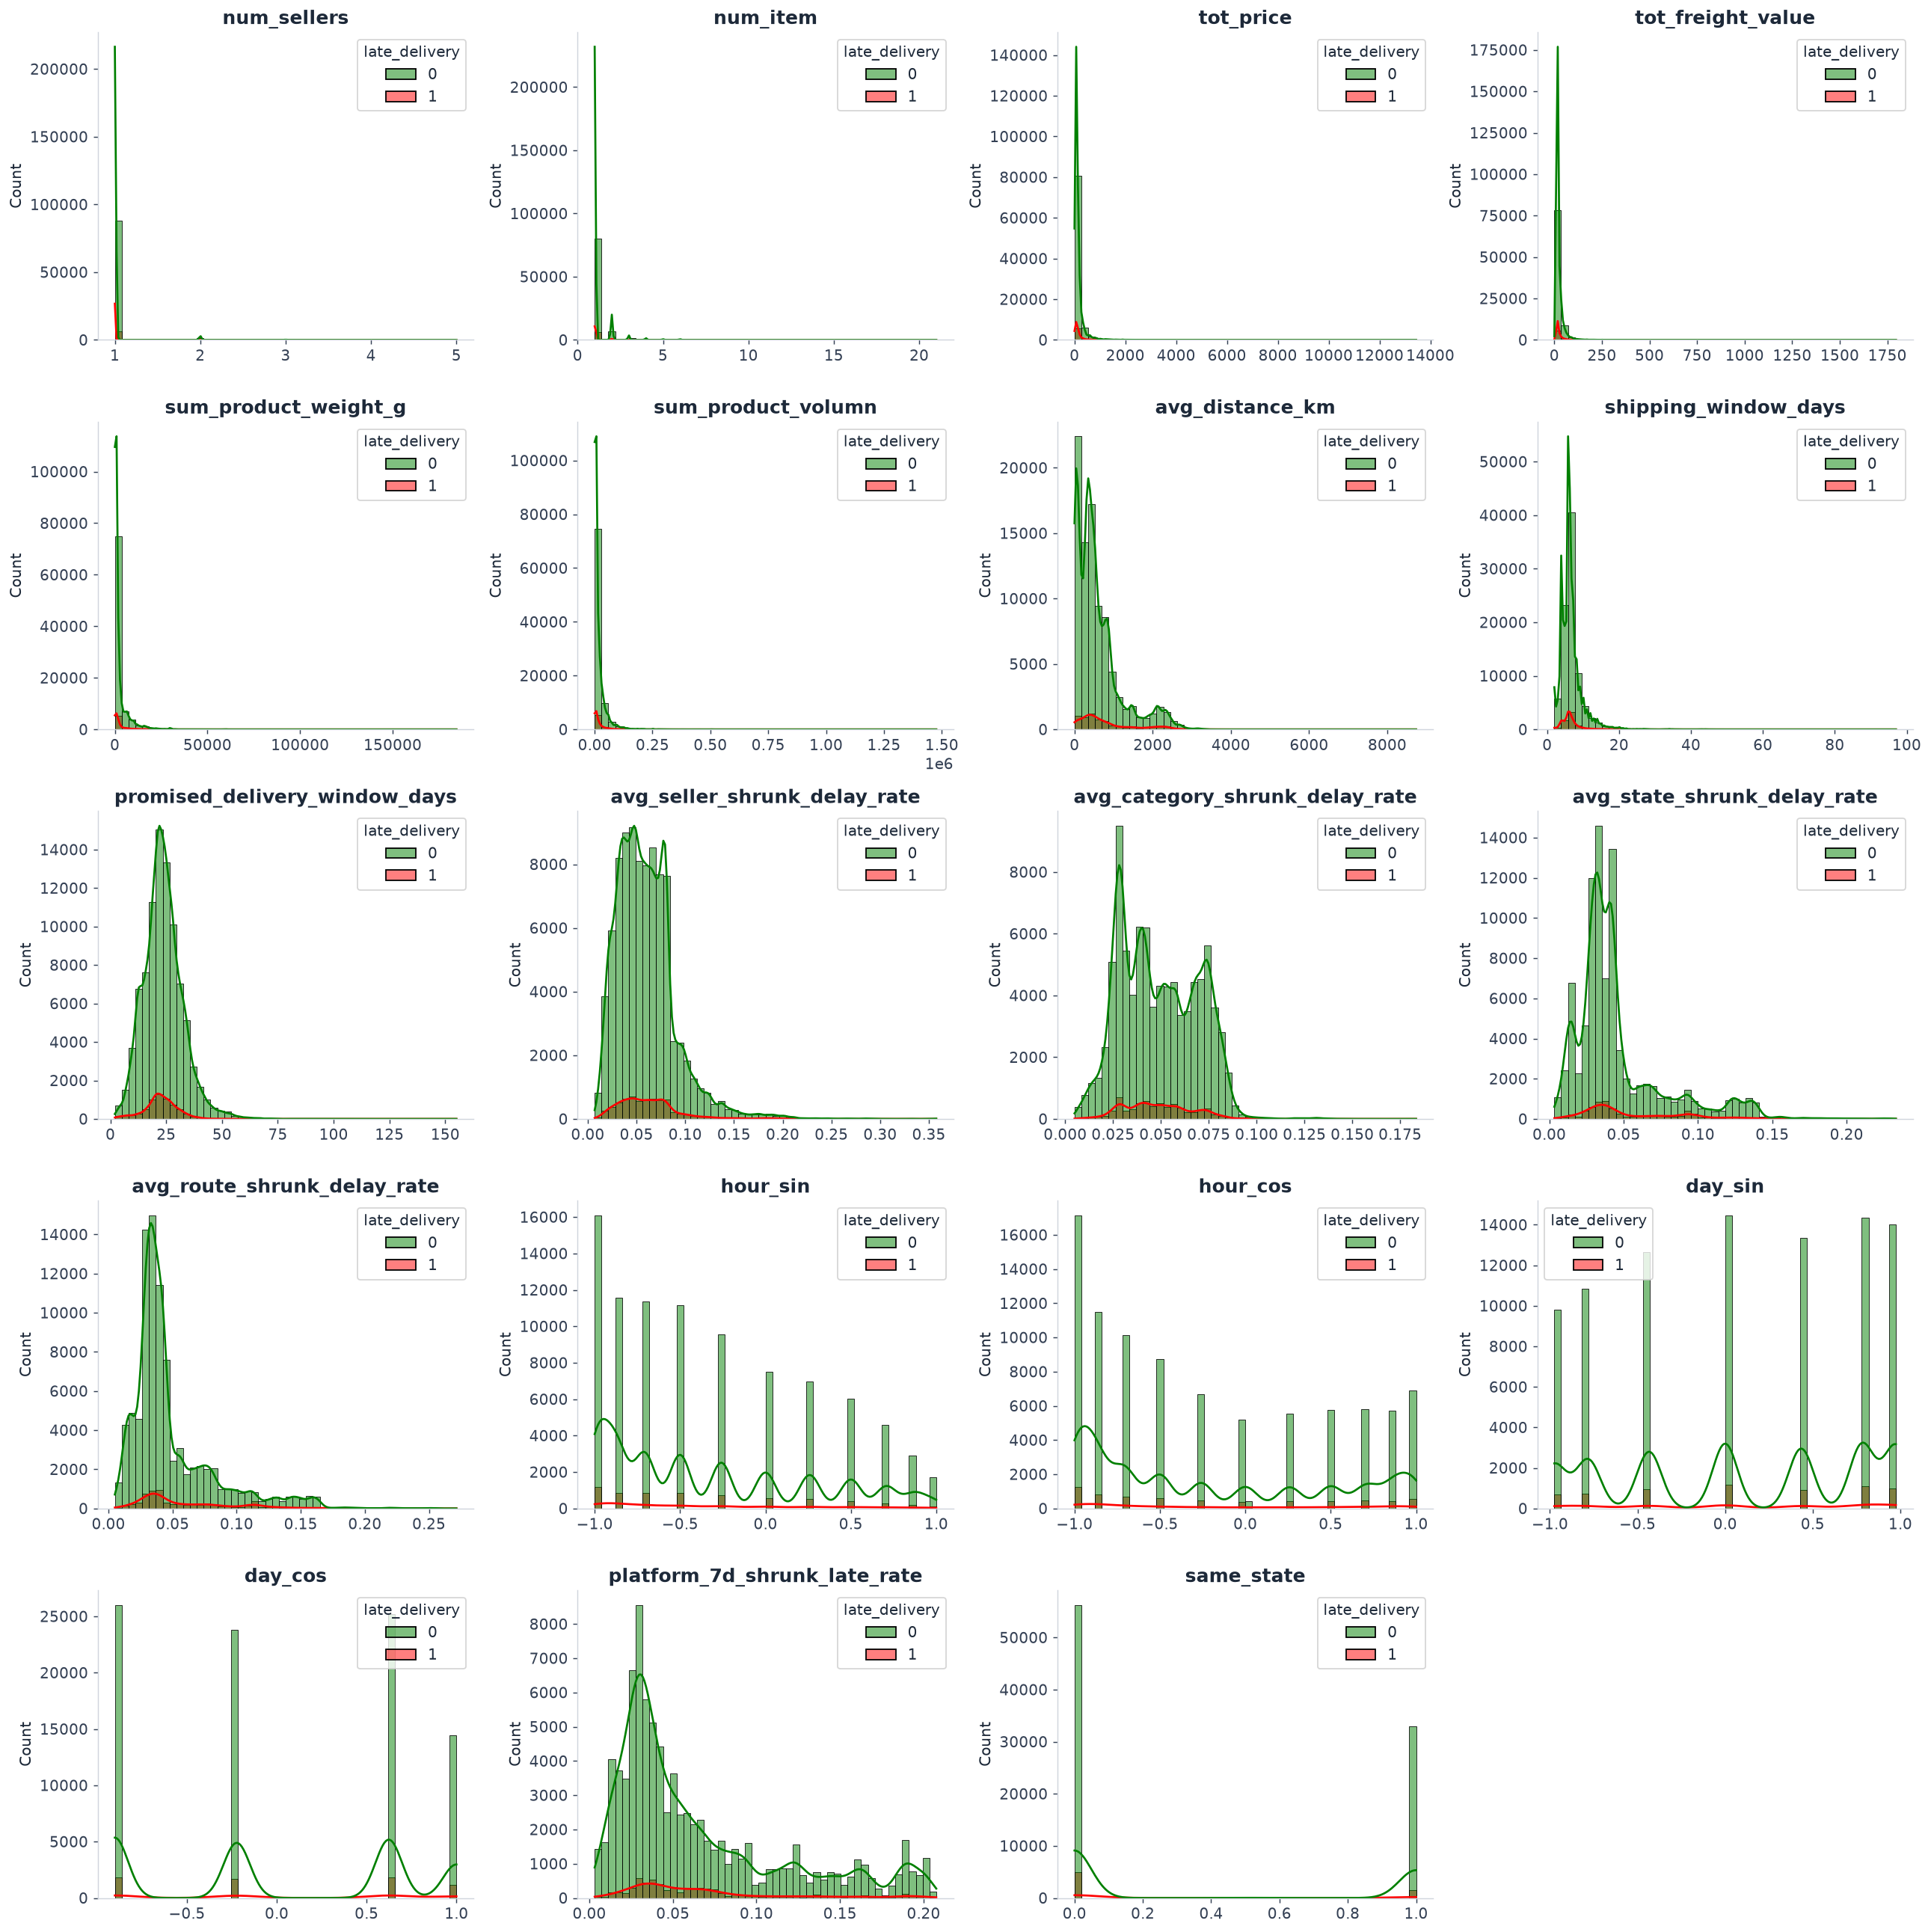

In [484]:
# Create a grid of subplots (e.g., 5 rows, 4 columns)
fig, axes = plt.subplots(nrows=5, ncols=4, figsize=(20, 20))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    # We drop NaNs just in case, and plot
    sns.histplot(
        data=df_full_v4, 
        x=col, 
        hue='late_delivery', 
        kde=True, # Adds a smooth curve over the bars
        ax=axes[i], 
        bins=50, 
        palette={0: "green", 1: "red"},
        alpha=0.5 # Transparency so overlapping bars are visible
    )
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('') # Remove x-label to save space

# Hide any empty subplots (if columns < grid size)
for j in range(len(continuous_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [485]:
df_full_v4['num_sellers'].describe()

count    95961.000000
mean         1.013870
std          0.123455
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          5.000000
Name: num_sellers, dtype: float64

In [486]:
df_full_v4['num_sellers'].value_counts()

num_sellers
1    94696
2     1206
3       54
4        3
5        2
Name: count, dtype: int64

In [487]:
df_full_v4['num_item'].describe()

count    95961.000000
mean         1.142297
std          0.539343
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
Name: num_item, dtype: float64

In [488]:
df_full_v4['num_item'].value_counts()

num_item
1     86377
2      7349
3      1302
4       492
5       192
6       191
7        22
8         8
10        8
12        5
11        4
9         3
20        2
15        2
14        2
13        1
21        1
Name: count, dtype: int64

In [489]:
df_full_v4['multi_seller'] = (df_full_v4['num_sellers'] > 1).astype(int)  # since it's mostly 1, we will change to one-hot encoding
df_full_v4['multi_item'] = (df_full_v4['num_item'] > 1).astype(int)

In [490]:
df_full_v4=df_full_v4.drop(columns=['num_sellers','num_item'])

In [491]:
df_full_v4.head()

,late_delivery,tot_price,tot_freight_value,sum_product_weight_g,sum_product_volumn,boleto,credit_card,debit_card,voucher,avg_distance_km,same_state,order_purchase_timestamp,shipping_window_days,promised_delivery_window_days,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,avg_seller_shrunk_delay_rate,avg_category_shrunk_delay_rate,avg_state_shrunk_delay_rate,avg_route_shrunk_delay_rate,hour_sin,hour_cos,day_sin,day_cos,platform_7d_shrunk_late_rate,multi_seller,multi_item
0,0,58.90,13.29,650.0,3528.0,0.0,1.0,0.0,0.0,301.005664,0.0,2017-09-13 08:59:02,6.0,16.0,0,0,0,0,0.027660,0.025965,0.030729,0.029652,0.866025,-0.500000,0.974928,-0.222521,0.031331,0,0
1,0,239.90,19.93,30000.0,60000.0,0.0,1.0,0.0,0.0,589.274140,1.0,2017-04-26 10:53:06,7.0,19.0,0,0,0,0,0.080000,0.021138,0.018914,0.019152,0.500000,-0.866025,0.974928,-0.222521,0.080503,0,0
2,0,199.00,17.87,3050.0,14157.0,0.0,1.0,0.0,0.0,312.495046,1.0,2018-01-14 14:33:31,4.0,21.0,0,0,0,0,0.066667,0.060435,0.024220,0.027394,-0.500000,-0.866025,-0.781831,0.623490,0.144577,0,0
3,0,12.99,12.79,200.0,2400.0,0.0,1.0,0.0,0.0,301.951753,1.0,2018-08-08 10:00:35,7.0,12.0,0,0,0,0,0.055172,0.063699,0.038882,0.039123,0.500000,-0.866025,0.974928,-0.222521,0.033551,0,0
4,0,199.90,18.14,3750.0,42000.0,0.0,1.0,0.0,0.0,646.221788,0.0,2017-02-04 13:57:51,9.0,40.0,0,0,0,0,0.072727,0.034783,0.012245,0.050000,-0.258819,-0.965926,-0.974928,-0.222521,0.007080,0,0


In [492]:
df_full_v4['same_state'].value_counts()

same_state
0.000000    61208
1.000000    34508
0.500000      183
0.333333       24
0.666667       19
0.750000        9
0.800000        3
0.250000        3
0.400000        1
0.600000        1
0.375000        1
0.833333        1
Name: count, dtype: int64

In [493]:
df_full_v4['late_delivery'].mean()

np.float64(0.06761080022092308)

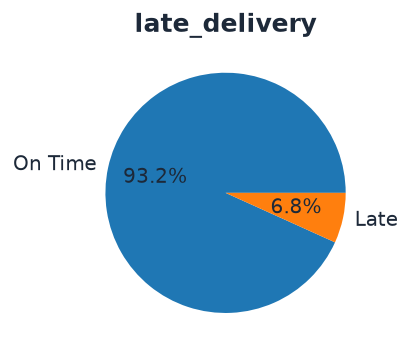

In [494]:
# Pie chart
fig = plt.figure(figsize=(3,3))
data=df_full_v4['late_delivery'].value_counts()
plt.pie(data,
        labels=['On Time' if x == 0 else 'Late' for x in data.index],
        autopct='%1.1f%%')

plt.title('late_delivery')
plt.show()

In [495]:

# 1. Distance × shipping window
df_full_v4["avg_distance_X_promised_shipping_window"] = (
    df_full_v4["avg_distance_km"]
    * df_full_v4["promised_delivery_window_days"]
)

# 2. Seller delay rate × shipping window
df_full_v4["avg_seller_shrunk_delay_rate_X_avg_distance_km"] = (
    df_full_v4["avg_seller_shrunk_delay_rate"]
    * df_full_v4["avg_distance_km"]
)


**Determine whether assumptions have been met**

The following are the assumptions for logistic regression:

* Independent observations (This refers to how the data was collected.)

* No extreme outliers

* Little to no multicollinearity among X predictors

* Linear relationship between X and the **logit** of y

For the first assumption, you can assume that observations are independent for this project.

The second assumption has already been addressed.

The last assumption will be verified after modeling.

**Note:** In practice, modeling assumptions are often violated, and depending on the specifics of your use case and the severity of the violation, it might not affect your model much at all or it will result in a failed model.

### Training、Validation & Test** 

In [496]:
df_full_v4.head()

,late_delivery,tot_price,tot_freight_value,sum_product_weight_g,sum_product_volumn,boleto,credit_card,debit_card,voucher,avg_distance_km,same_state,order_purchase_timestamp,shipping_window_days,promised_delivery_window_days,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,avg_seller_shrunk_delay_rate,avg_category_shrunk_delay_rate,avg_state_shrunk_delay_rate,avg_route_shrunk_delay_rate,hour_sin,hour_cos,day_sin,day_cos,platform_7d_shrunk_late_rate,multi_seller,multi_item,avg_distance_X_promised_shipping_window,avg_seller_shrunk_delay_rate_X_avg_distance_km
0,0,58.90,13.29,650.0,3528.0,0.0,1.0,0.0,0.0,301.005664,0.0,2017-09-13 08:59:02,6.0,16.0,0,0,0,0,0.027660,0.025965,0.030729,0.029652,0.866025,-0.500000,0.974928,-0.222521,0.031331,0,0,4816.090629,8.325689
1,0,239.90,19.93,30000.0,60000.0,0.0,1.0,0.0,0.0,589.274140,1.0,2017-04-26 10:53:06,7.0,19.0,0,0,0,0,0.080000,0.021138,0.018914,0.019152,0.500000,-0.866025,0.974928,-0.222521,0.080503,0,0,11196.208666,47.141931
2,0,199.00,17.87,3050.0,14157.0,0.0,1.0,0.0,0.0,312.495046,1.0,2018-01-14 14:33:31,4.0,21.0,0,0,0,0,0.066667,0.060435,0.024220,0.027394,-0.500000,-0.866025,-0.781831,0.623490,0.144577,0,0,6562.395967,20.833003
3,0,12.99,12.79,200.0,2400.0,0.0,1.0,0.0,0.0,301.951753,1.0,2018-08-08 10:00:35,7.0,12.0,0,0,0,0,0.055172,0.063699,0.038882,0.039123,0.500000,-0.866025,0.974928,-0.222521,0.033551,0,0,3623.421040,16.659407
4,0,199.90,18.14,3750.0,42000.0,0.0,1.0,0.0,0.0,646.221788,0.0,2017-02-04 13:57:51,9.0,40.0,0,0,0,0,0.072727,0.034783,0.012245,0.050000,-0.258819,-0.965926,-0.974928,-0.222521,0.007080,0,0,25848.871529,46.997948


In [497]:
df_full_multicol = df_full_v4.drop(columns=[
    'late_delivery', 
    'order_purchase_timestamp'
])

In [498]:
df_full_multicol.head()

,tot_price,tot_freight_value,sum_product_weight_g,sum_product_volumn,boleto,credit_card,debit_card,voucher,avg_distance_km,same_state,shipping_window_days,promised_delivery_window_days,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,avg_seller_shrunk_delay_rate,avg_category_shrunk_delay_rate,avg_state_shrunk_delay_rate,avg_route_shrunk_delay_rate,hour_sin,hour_cos,day_sin,day_cos,platform_7d_shrunk_late_rate,multi_seller,multi_item,avg_distance_X_promised_shipping_window,avg_seller_shrunk_delay_rate_X_avg_distance_km
0,58.90,13.29,650.0,3528.0,0.0,1.0,0.0,0.0,301.005664,0.0,6.0,16.0,0,0,0,0,0.027660,0.025965,0.030729,0.029652,0.866025,-0.500000,0.974928,-0.222521,0.031331,0,0,4816.090629,8.325689
1,239.90,19.93,30000.0,60000.0,0.0,1.0,0.0,0.0,589.274140,1.0,7.0,19.0,0,0,0,0,0.080000,0.021138,0.018914,0.019152,0.500000,-0.866025,0.974928,-0.222521,0.080503,0,0,11196.208666,47.141931
2,199.00,17.87,3050.0,14157.0,0.0,1.0,0.0,0.0,312.495046,1.0,4.0,21.0,0,0,0,0,0.066667,0.060435,0.024220,0.027394,-0.500000,-0.866025,-0.781831,0.623490,0.144577,0,0,6562.395967,20.833003
3,12.99,12.79,200.0,2400.0,0.0,1.0,0.0,0.0,301.951753,1.0,7.0,12.0,0,0,0,0,0.055172,0.063699,0.038882,0.039123,0.500000,-0.866025,0.974928,-0.222521,0.033551,0,0,3623.421040,16.659407
4,199.90,18.14,3750.0,42000.0,0.0,1.0,0.0,0.0,646.221788,0.0,9.0,40.0,0,0,0,0,0.072727,0.034783,0.012245,0.050000,-0.258819,-0.965926,-0.974928,-0.222521,0.007080,0,0,25848.871529,46.997948


In [499]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

In [500]:
%%time
X = df_full_multicol

# 3. Add a constant column — REQUIRED, otherwise VIF is meaningless
X_const = add_constant(X)

# 4. Compute VIF for each feature
vif = pd.DataFrame({
    "feature": X_const.columns,
    "VIF": [variance_inflation_factor(X_const.values, i)
            for i in range(X_const.shape[1])]
})

print(vif.sort_values("VIF", ascending=False))

<timed exec>:9: UserWarning: The design matrix is poorly conditioned (condition number=6.24e+14). VIF calculations may be numerically unstable.
C:\Users\Ed\miniconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Ed\miniconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Ed\miniconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\Ed\miniconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient.

                                           feature           VIF
5                                           boleto  1.000800e+15
6                                      credit_card  1.000800e+15
7                                       debit_card  1.000800e+15
8                                          voucher  1.000800e+15
9                                  avg_distance_km  1.745719e+01
28         avg_distance_X_promised_shipping_window  1.595696e+01
29  avg_seller_shrunk_delay_rate_X_avg_distance_km  5.457594e+00
19                     avg_state_shrunk_delay_rate  4.483817e+00
20                     avg_route_shrunk_delay_rate  4.435382e+00
3                             sum_product_weight_g  3.582892e+00
4                               sum_product_volumn  3.525696e+00
12                   promised_delivery_window_days  3.204749e+00
2                                tot_freight_value  2.751721e+00
17                    avg_seller_shrunk_delay_rate  2.279182e+00
10                       

C:\Users\Ed\miniconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


In [501]:
df_full_v4['order_purchase_timestamp'] = pd.to_datetime(df_full_v4['order_purchase_timestamp'])
df_full_v4['month'] = df_full_v4['order_purchase_timestamp'].dt.to_period('M')

monthly = (
    df_full_v4.groupby('month')
    .agg(
        n=('late_delivery', 'size'),
        late_orders=('late_delivery', 'sum'),
        late_rate=('late_delivery', 'mean')
    )
    .reset_index()
)
monthly['late_rate'] = monthly['late_rate'].round(4)
monthly

,month,n,late_orders,late_rate
0,2016-10,265,2,0.0075
1,2016-12,1,0,0.0000
2,2017-01,747,22,0.0295
3,2017-02,1641,49,0.0299
4,2017-03,2533,115,0.0454
5,2017-04,2283,148,0.0648
6,2017-05,3526,104,0.0295
7,2017-06,3112,95,0.0305
8,2017-07,3851,107,0.0278
9,2017-08,4168,121,0.0290


# Model development

In [502]:
df_full_v5 = df_full_v4.copy()

In [503]:
df_full_v5 = df_full_v5.sort_values('order_purchase_timestamp')
df_full_v5.head()

,late_delivery,tot_price,tot_freight_value,sum_product_weight_g,sum_product_volumn,boleto,credit_card,debit_card,voucher,avg_distance_km,same_state,order_purchase_timestamp,shipping_window_days,promised_delivery_window_days,is_public_holiday,is_carnival,is_black_friday,is_christmas_period,avg_seller_shrunk_delay_rate,avg_category_shrunk_delay_rate,avg_state_shrunk_delay_rate,avg_route_shrunk_delay_rate,hour_sin,hour_cos,day_sin,day_cos,platform_7d_shrunk_late_rate,multi_seller,multi_item,avg_distance_X_promised_shipping_window,avg_seller_shrunk_delay_rate_X_avg_distance_km,month
22237,0,29.90,15.56,300.0,4096.0,1.0,0.0,0.0,0.0,708.910836,0.0,2016-10-03 09:44:50,18.0,24.0,0,0,0,0,0.08,0.08,0.08,0.08,0.707107,-0.707107,0.0,1.0,0.08,0,0,17013.860058,56.712867,2016-10
71326,0,21.90,17.19,400.0,4096.0,1.0,0.0,0.0,0.0,916.383280,0.0,2016-10-03 16:56:50,18.0,34.0,0,0,0,0,0.08,0.08,0.08,0.08,-0.866025,-0.500000,0.0,1.0,0.08,0,0,31157.031517,73.310662,2016-10
61205,0,36.49,17.24,767.0,4160.0,1.0,0.0,0.0,0.0,818.484261,0.0,2016-10-03 21:13:36,18.0,56.0,0,0,0,0,0.08,0.08,0.08,0.08,-0.707107,0.707107,0.0,1.0,0.08,0,0,45835.118626,65.478741,2016-10
78815,0,119.90,13.56,2050.0,14960.0,0.0,1.0,0.0,0.0,212.176837,1.0,2016-10-03 22:06:03,18.0,50.0,0,0,0,0,0.08,0.08,0.08,0.08,-0.500000,0.866025,0.0,1.0,0.08,0,0,10608.841851,16.974147,2016-10
76943,0,29.99,10.96,9000.0,2640.0,0.0,1.0,0.0,0.0,191.771897,1.0,2016-10-03 22:31:31,5.0,50.0,0,0,0,0,0.08,0.08,0.08,0.08,-0.500000,0.866025,0.0,1.0,0.08,0,0,9588.594861,15.341752,2016-10


In [504]:
# 2. Reserve the latest 20% as test set
split_idx = int(len(df_full_v5) * 0.8)
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, roc_auc_score,
    average_precision_score, precision_recall_curve
)
from xgboost import XGBClassifier

df_full_v5['order_purchase_timestamp'] = pd.to_datetime(df_full_v5['order_purchase_timestamp'])
d = df_full_v5['order_purchase_timestamp']

train = df_full_v5[d < '2018-03-01']          # 正常
valid = df_full_v5[(d >= '2018-03-01') & (d < '2018-06-01')]  # 含 3 月危机 + 5 月罢工
test  = df_full_v5[d >= '2018-06-01']         # 从 6 月极低迟到率开始

features = [
    'tot_price', 'tot_freight_value', 'sum_product_weight_g', 'sum_product_volumn',
    'boleto', 'credit_card', 'debit_card', 'voucher',
    'avg_distance_km', 'same_state',
    'shipping_window_days', 'promised_delivery_window_days',
    'is_public_holiday', 'is_carnival', 'is_black_friday', 'is_christmas_period',
    'avg_seller_shrunk_delay_rate', 'avg_category_shrunk_delay_rate',
    'avg_state_shrunk_delay_rate', 'avg_route_shrunk_delay_rate',
    'hour_sin', 'hour_cos', 'day_sin', 'day_cos',
    'platform_7d_shrunk_late_rate',
    'multi_seller', 'multi_item',
    'avg_distance_X_promised_shipping_window',
    'avg_seller_shrunk_delay_rate_X_avg_distance_km',
]

skewed = [
    'tot_price', 'tot_freight_value', 'sum_product_weight_g', 'sum_product_volumn',
    'avg_distance_km', 'shipping_window_days', 'promised_delivery_window_days',
    'avg_distance_X_promised_shipping_window',
    'avg_seller_shrunk_delay_rate_X_avg_distance_km',
]
for c in skewed:
    train[c] = np.log1p(train[c].clip(lower=0))
    valid[c] = np.log1p(valid[c].clip(lower=0))
    test[c] = np.log1p(test[c].clip(lower=0))

X_train, y_train = train[features], train['late_delivery'].astype(int)
X_valid, y_valid = valid[features], valid['late_delivery'].astype(int)
X_test,  y_test  = test[features],  test['late_delivery'].astype(int)

scale_pos = (y_train == 0).sum() / max((y_train == 1).sum(), 1)

def best_threshold(y_true, proba):
    p, r, t = precision_recall_curve(y_true, proba)
    f1 = 2 * p * r / (p + r + 1e-12)
    idx = np.nanargmax(f1[:-1])
    return t[idx], f1[idx]

results = []

In [505]:
logit = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
logit.fit(X_train, y_train)

proba_v = logit.predict_proba(X_valid)[:, 1]
proba_t = logit.predict_proba(X_test)[:, 1]
thr, _ = best_threshold(y_valid, proba_v)
pred_t = (proba_t >= thr).astype(int)

results.append({
    'model': 'Logistic',
    'valid_PR_AUC': average_precision_score(y_valid, proba_v),
    'valid_ROC_AUC': roc_auc_score(y_valid, proba_v),
    'best_thr': thr,
    'test_PR_AUC': average_precision_score(y_test, proba_t),
    'test_ROC_AUC': roc_auc_score(y_test, proba_t),
})
print(f'Logistic | thr={thr:.3f}')
print(classification_report(y_test, pred_t, digits=3))

Logistic | thr=0.702
              precision    recall  f1-score   support

           0      0.988     0.478     0.644     17860
           1      0.057     0.842     0.106       665

    accuracy                          0.491     18525
   macro avg      0.522     0.660     0.375     18525
weighted avg      0.954     0.491     0.625     18525



In [506]:
from sklearn.model_selection import ParameterGrid

grid = ParameterGrid({
    'max_depth': [6, 8, 10],
    'min_samples_leaf': [20, 50, 100],
})

best = None
for params in grid:
    rf = RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        **params
    )
    rf.fit(X_train, y_train)
    proba_v = rf.predict_proba(X_valid)[:, 1]
    score = average_precision_score(y_valid, proba_v)
    if best is None or score > best[0]:
        best = (score, params)

print(best)

(0.21249118476329837, {'max_depth': 10, 'min_samples_leaf': 50})


In [507]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, min_samples_leaf=50,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf.fit(X_train, y_train)

proba_v = rf.predict_proba(X_valid)[:, 1]
proba_t = rf.predict_proba(X_test)[:, 1]
thr, _ = best_threshold(y_valid, proba_v)
pred_t = (proba_t >= thr).astype(int)

results.append({
    'model': 'RandomForest',
    'valid_PR_AUC': average_precision_score(y_valid, proba_v),
    'valid_ROC_AUC': roc_auc_score(y_valid, proba_v),
    'best_thr': thr,
    'test_PR_AUC': average_precision_score(y_test, proba_t),
    'test_ROC_AUC': roc_auc_score(y_test, proba_t),
})
print(f'RandomForest | thr={thr:.3f}')
print(classification_report(y_test, pred_t, digits=3))

RandomForest | thr=0.641
              precision    recall  f1-score   support

           0      0.963     0.817     0.884     17860
           1      0.033     0.167     0.055       665

    accuracy                          0.794     18525
   macro avg      0.498     0.492     0.470     18525
weighted avg      0.930     0.794     0.855     18525



In [508]:
from sklearn.model_selection import ParameterGrid

grid = ParameterGrid({
    'max_depth': [3, 4, 6],
    'learning_rate': [0.03, 0.05, 0.1],
    'min_child_weight': [1, 5, 10],
})

best = None
for params in grid:
    xgb = XGBClassifier(
        n_estimators=300,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos,
        eval_metric='aucpr',
        random_state=42,
        n_jobs=-1,
        **params
    )
    xgb.fit(X_train, y_train)
    proba_v = xgb.predict_proba(X_valid)[:, 1]
    score = average_precision_score(y_valid, proba_v)
    if best is None or score > best[0]:
        best = (score, params)

print(best)

(0.22458566466688873, {'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 1})


In [509]:
xgb = XGBClassifier(
    n_estimators=300, max_depth=3, learning_rate=0.1,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos, eval_metric='aucpr',
    random_state=42, n_jobs=-1, min_child_weight=1
)
xgb.fit(X_train, y_train)

proba_v = xgb.predict_proba(X_valid)[:, 1]
proba_t = xgb.predict_proba(X_test)[:, 1]
thr, _ = best_threshold(y_valid, proba_v)
pred_t = (proba_t >= thr).astype(int)

results.append({
    'model': 'XGBoost',
    'valid_PR_AUC': average_precision_score(y_valid, proba_v),
    'valid_ROC_AUC': roc_auc_score(y_valid, proba_v),
    'best_thr': thr,
    'test_PR_AUC': average_precision_score(y_test, proba_t),
    'test_ROC_AUC': roc_auc_score(y_test, proba_t),
})
print(f'XGBoost | thr={thr:.3f}')
print(classification_report(y_test, pred_t, digits=3))

XGBoost | thr=0.655
              precision    recall  f1-score   support

           0      0.965     0.738     0.836     17860
           1      0.038     0.280     0.067       665

    accuracy                          0.721     18525
   macro avg      0.502     0.509     0.452     18525
weighted avg      0.932     0.721     0.809     18525



In [510]:
pd.DataFrame(results).round(4)

,model,valid_PR_AUC,valid_ROC_AUC,best_thr,test_PR_AUC,test_ROC_AUC
0,Logistic,0.1723,0.6765,0.7021,0.0912,0.7296
1,RandomForest,0.2116,0.6760,0.6413,0.0312,0.4258
2,XGBoost,0.2192,0.7031,0.6549,0.0389,0.5335


Logistic will be our champion model

# Model application

In [513]:
# 确保有 route 收缩率（如果订单层列名是 avg_route_shrunk_delay_rate 就改这里）
if 'route_shrunk_delay_rate' in df_full_v5.columns and 'avg_route_shrunk_delay_rate' not in features:
    features = features + ['route_shrunk_delay_rate']

months = pd.period_range('2018-03', '2018-08', freq='M')
rows = []

for m in months:
    tr = df_full_v5[df_full_v5['order_purchase_timestamp'] < m.start_time].copy()
    te = df_full_v5[
        (df_full_v5['order_purchase_timestamp'] >= m.start_time) &
        (df_full_v5['order_purchase_timestamp'] < m.end_time + pd.Timedelta(days=1))
    ].copy()

    if te['late_delivery'].sum() < 30:
        continue

    for c in skewed:
        if c in tr.columns:
            tr[c] = np.log1p(tr[c].clip(lower=0))
            te[c] = np.log1p(te[c].clip(lower=0))

    use_cols = [c for c in features if c in tr.columns]

    logit = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
    ])
    logit.fit(tr[use_cols], tr['late_delivery'].astype(int))
    proba = logit.predict_proba(te[use_cols])[:, 1]
    y_te = te['late_delivery'].astype(int)

    # 前 10% 迟到率
    k = max(int(0.1 * len(y_te)), 1)
    top_rate = y_te.iloc[np.argsort(proba)[::-1][:k]].mean()

    rows.append({
        'test_month': str(m),
        'n': len(te),
        'late_rate': round(y_te.mean(), 4),
        'PR_AUC': round(average_precision_score(y_te, proba), 4),
        'ROC_AUC': round(roc_auc_score(y_te, proba), 4),
        'top10_late_rate': round(top_rate, 4),
    })

pd.DataFrame(rows)

,test_month,n,late_rate,PR_AUC,ROC_AUC,top10_late_rate
0,2018-03,7170,0.1863,0.3598,0.7106,0.4672
1,2018-04,7015,0.0448,0.1379,0.7795,0.1598
2,2018-05,6900,0.0641,0.1570,0.7435,0.1986
3,2018-06,6224,0.0112,0.0549,0.7823,0.0402
4,2018-07,6438,0.0362,0.1010,0.6883,0.1198
5,2018-08,6323,0.0617,0.1506,0.7039,0.1725


In [514]:
# 用最近一次滚动里表现稳定的月份，或直接用测试集
# 这里用 2018-08 举例；想看其他月改月份即可

month = '2018-08'
te = df_full_v5[
    df_full_v5['order_purchase_timestamp'].dt.to_period('M').astype(str) == month
].copy()

# 用该月之前的数据训练
tr = df_full_v5[df_full_v5['order_purchase_timestamp'] < te['order_purchase_timestamp'].min()].copy()

for c in skewed:
    if c in tr.columns:
        tr[c] = np.log1p(tr[c].clip(lower=0))
        te[c] = np.log1p(te[c].clip(lower=0))

use_cols = [c for c in features if c in tr.columns]

logit = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
logit.fit(tr[use_cols], tr['late_delivery'].astype(int))

te = te.copy()
te['pred_proba'] = logit.predict_proba(te[use_cols])[:, 1]
te['actual_late'] = te['late_delivery'].astype(int)

# 前 10%
k = max(int(0.1 * len(te)), 1)
top = te.nlargest(k, 'pred_proba')[
    ['order_purchase_timestamp', 'pred_proba', 'actual_late',
     'promised_delivery_window_days', 'avg_distance_km']
].copy()

top['pred_rank'] = range(1, len(top) + 1)
top['hit'] = top['actual_late'].map({1: '迟到', 0: '准时'})

print(f'{month} Top 10%：{k} order')
print(f'Among them, those who were truly late：{top["actual_late"].sum()} order')
print(f'Lateness rate among the top 10%：{top["actual_late"].mean():.2%}')
print(f'Overall tardiness rate for the month：{te["actual_late"].mean():.2%}')
print(f'Overall number of late delivery for the month：{te['actual_late'].sum()}')
print()
top.head(20)

2018-08 Top 10%：632 order
Among them, those who were truly late：109 order
Lateness rate among the top 10%：17.25%
Overall tardiness rate for the month：6.17%
Overall number of late delivery for the month：390



,order_purchase_timestamp,pred_proba,actual_late,promised_delivery_window_days,avg_distance_km,pred_rank,hit
60443,2018-08-01 12:28:56,0.979305,0,2.197225,7.022692,1,准时
45733,2018-08-14 22:43:55,0.978035,0,1.098612,5.306195,2,准时
78441,2018-08-02 15:46:16,0.977836,1,2.079442,6.390946,3,迟到
75771,2018-08-15 10:06:15,0.964114,0,1.791759,6.084252,4,准时
63359,2018-08-20 14:31:33,0.963247,0,1.098612,4.223934,5,准时
55093,2018-08-28 16:33:22,0.961648,0,1.098612,4.419421,6,准时
60537,2018-08-21 21:15:52,0.960474,0,1.098612,4.403648,7,准时
53854,2018-08-07 16:08:48,0.959603,1,1.098612,4.328522,8,迟到
84674,2018-08-24 18:26:00,0.956477,1,1.609438,5.133887,9,迟到
15240,2018-08-27 17:10:36,0.956038,0,1.098612,4.473902,10,准时


In [515]:
summary = pd.DataFrame({
    'Range': ['Overall', 'Model Top 10%'],
    'Number of Order': [len(te), k],
    'Number of late delivery': [te['actual_late'].sum(), top['actual_late'].sum()],
    'Late delivery rate': [te['actual_late'].mean(), top['actual_late'].mean()]
})
summary['Late delivery rate'] = summary['Late delivery rate'].map(lambda x: f'{x:.2%}')
summary

,Range,Number of Order,Number of late delivery,Late delivery rate
0,Overall,6323,390,6.17%
1,Model Top 10%,632,109,17.25%


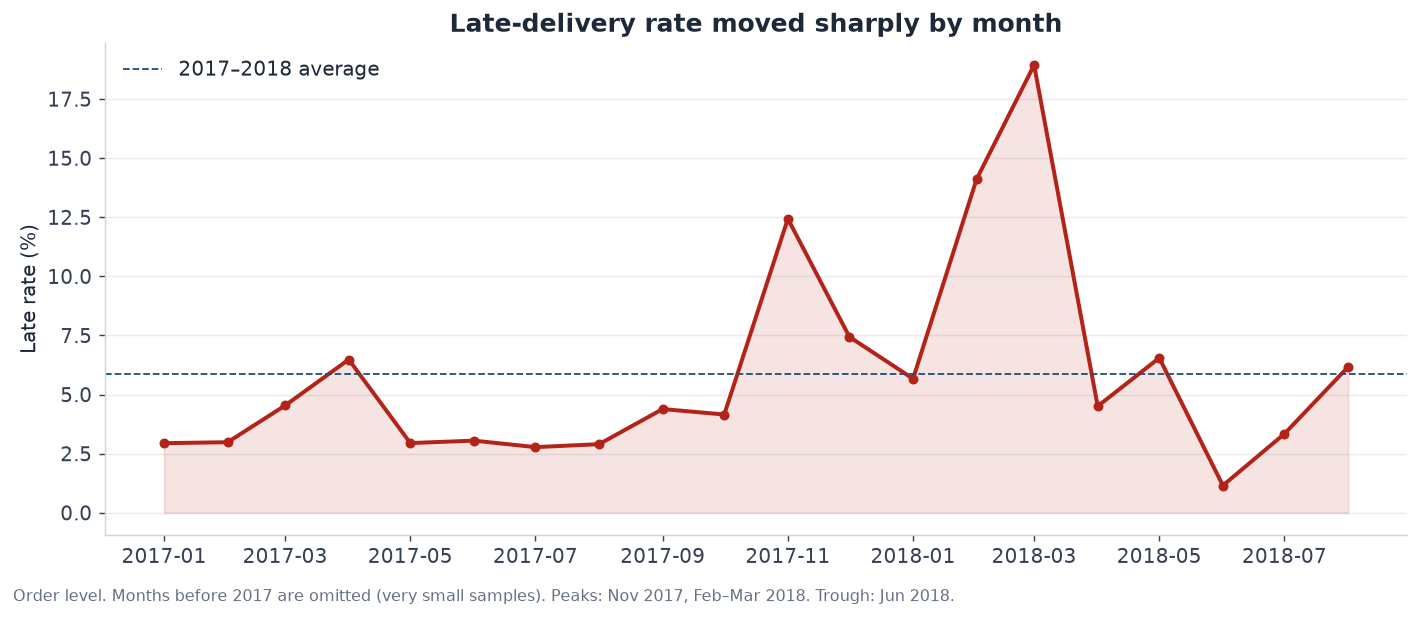

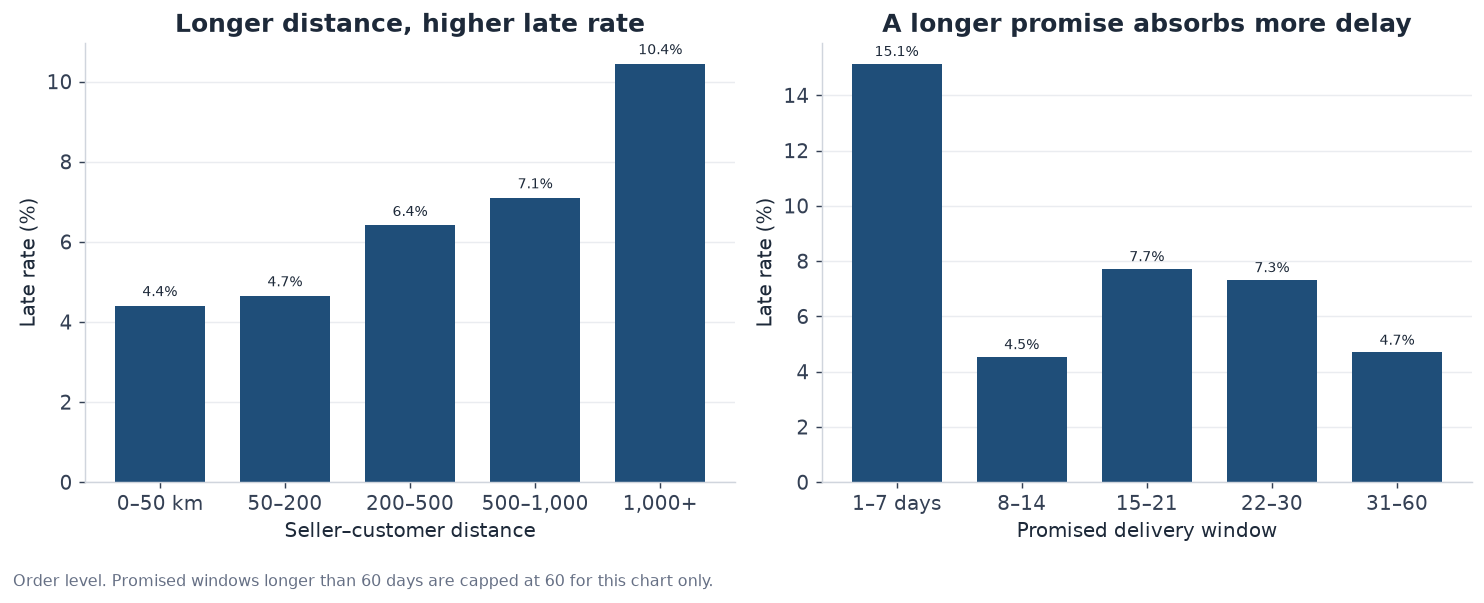

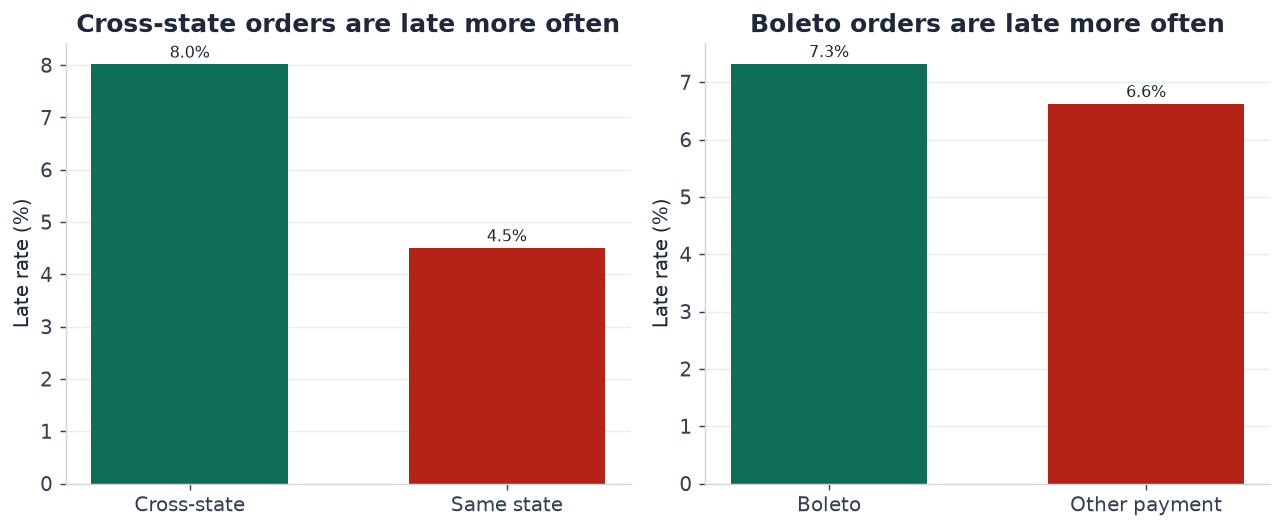

  month    n  late_rate  pr_auc  roc_auc
2018-03 6969     0.1894  0.3623   0.7107
2018-04 6763     0.0451  0.1373   0.7774
2018-05 6716     0.0655  0.1581   0.7388
2018-06 6068     0.0115  0.0571   0.7839
2018-07 6134     0.0334  0.0978   0.6817
2018-08 6323     0.0617  0.1506   0.7039


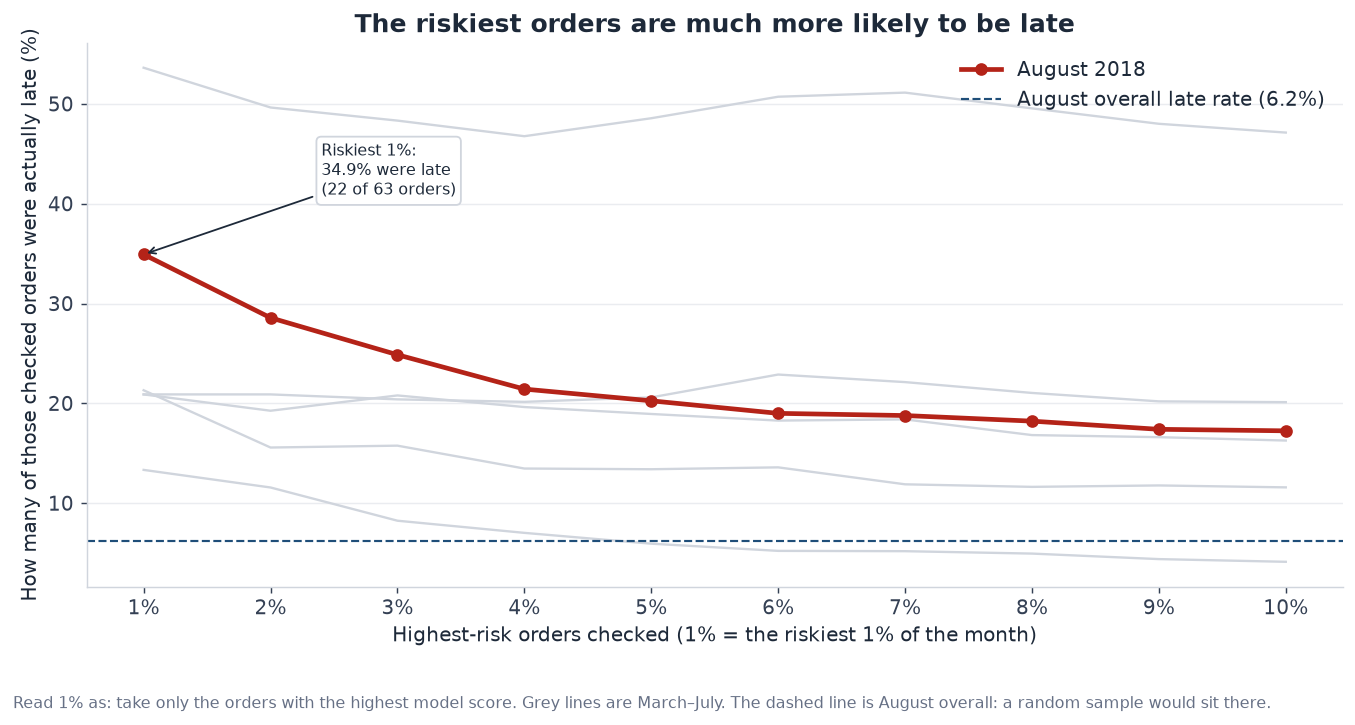

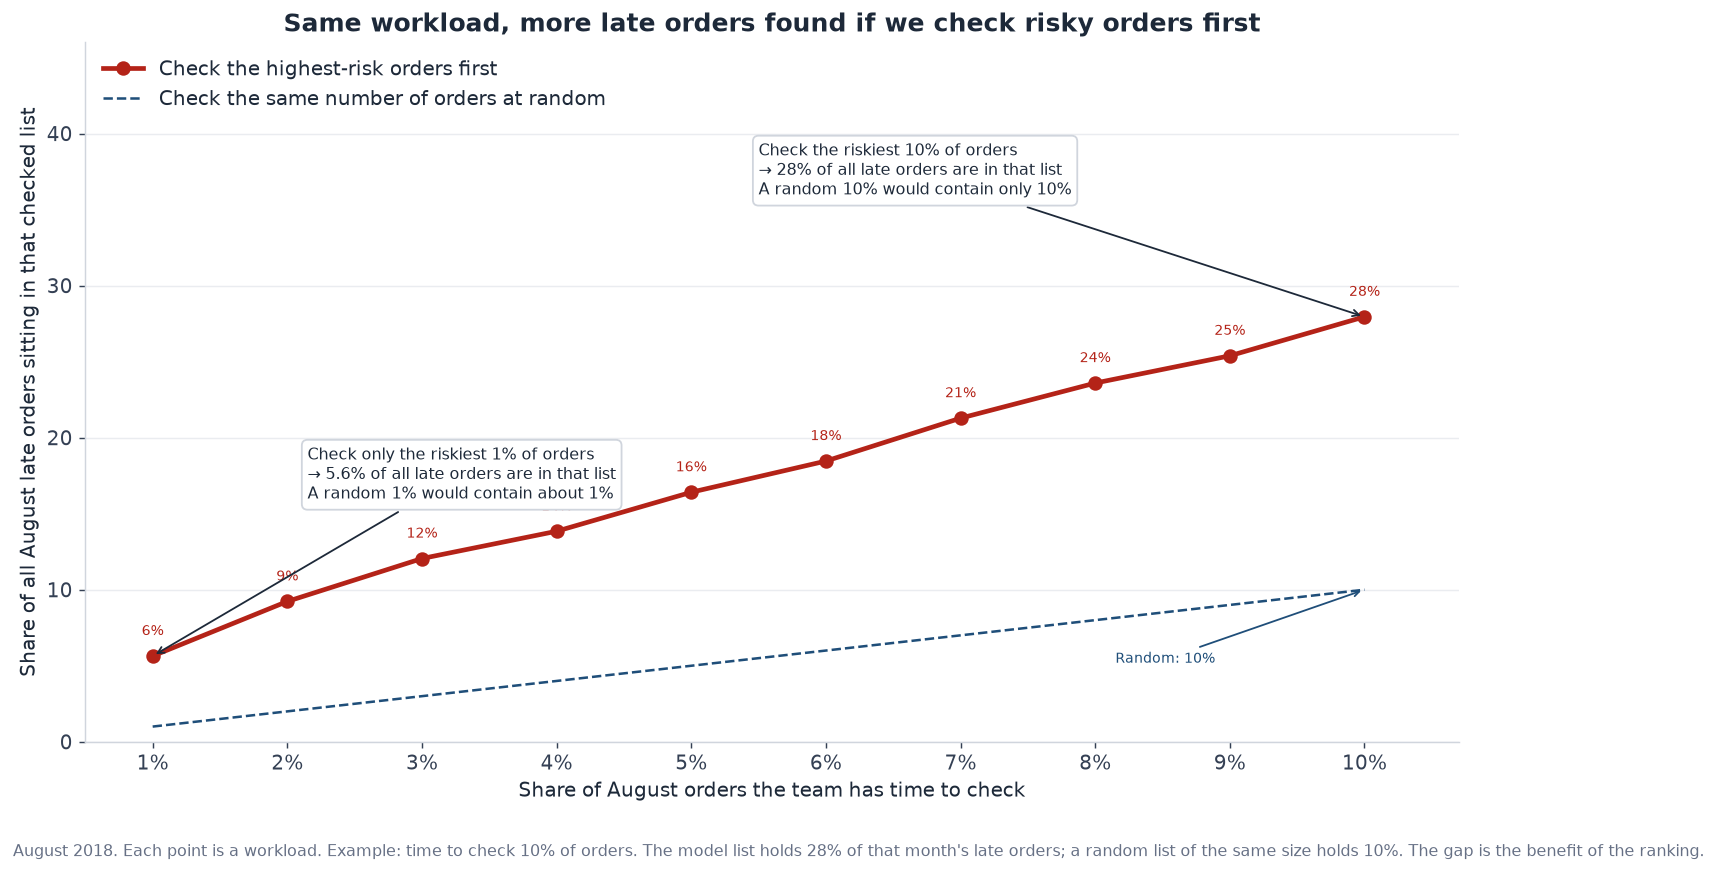

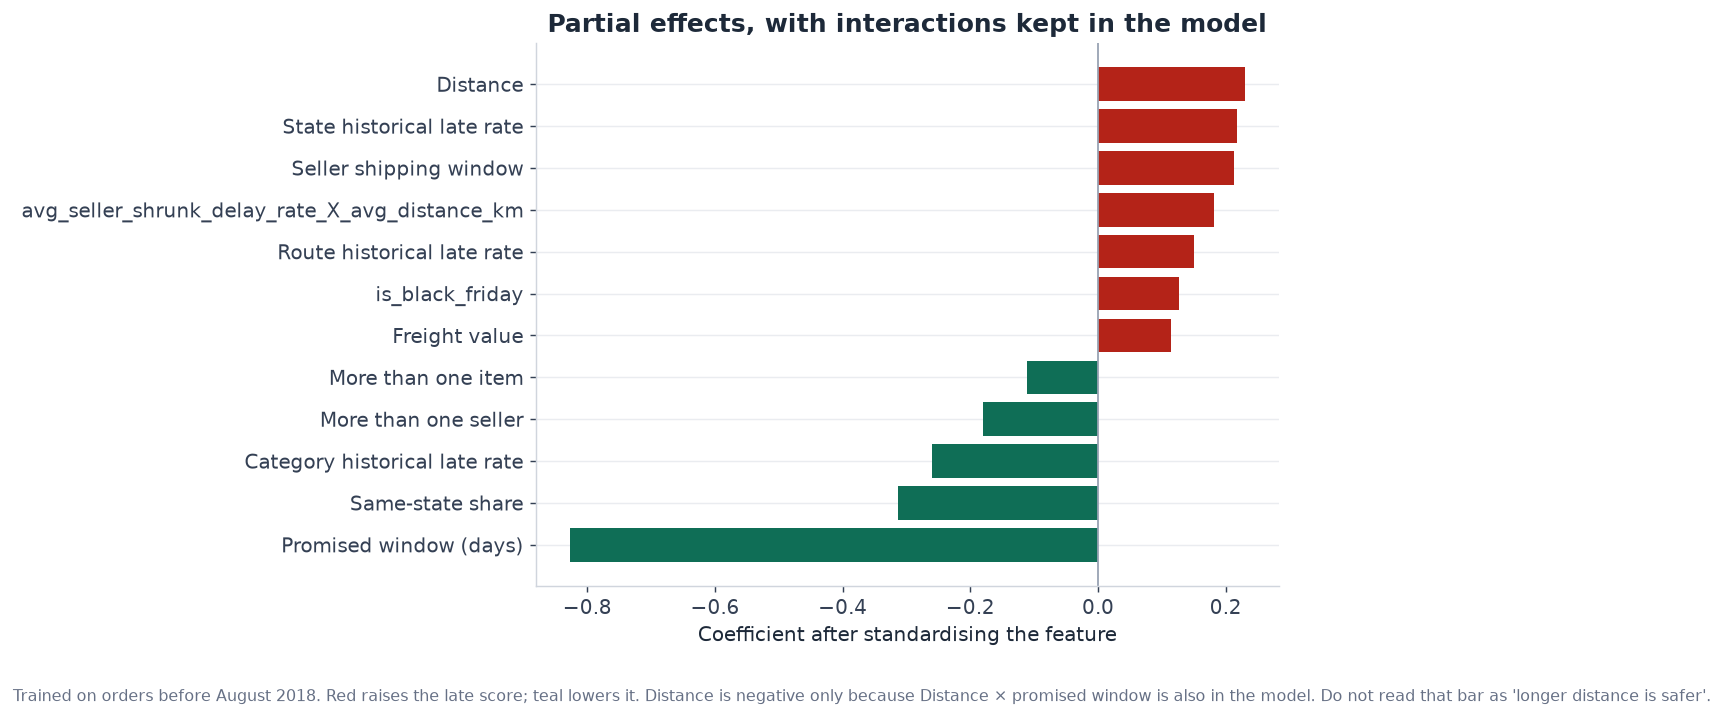

In [516]:
# Paste into the notebook AFTER df_full_v1, df_full_v5, features, and skewed exist.
# Charts are in English. Nothing here is labelled "accuracy":
# the useful number is the actual late rate inside the highest-risk slice.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, roc_auc_score

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#D0D5DD",
    "axes.labelcolor": "#1D2939",
    "xtick.color": "#344054",
    "ytick.color": "#344054",
    "text.color": "#1D2939",
    "axes.titleweight": "semibold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 130,
    "savefig.bbox": "tight",
})

NAVY = "#1F4E79"
RED = "#B42318"
TEAL = "#0F6E56"
GRID = "#EAECF0"
INK = "#1D2939"


def _style(ax):
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.xaxis.grid(False)


# =============================================================================
# PART 1 — Exploration
# =============================================================================

# --- 1. Monthly late rate (order level) ---
eda = df_full_v5.copy()
eda["order_purchase_timestamp"] = pd.to_datetime(eda["order_purchase_timestamp"])
eda["month"] = eda["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
monthly = (
    eda.groupby("month", as_index=False)
    .agg(orders=("late_delivery", "size"), late_rate=("late_delivery", "mean"))
)
monthly = monthly[monthly["month"] >= "2017-01-01"].copy()

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.fill_between(monthly["month"], monthly["late_rate"] * 100, color=RED, alpha=0.12)
ax.plot(monthly["month"], monthly["late_rate"] * 100, color=RED, lw=2.2, marker="o", ms=4.5)
ax.axhline(monthly["late_rate"].mean() * 100, color=NAVY, ls="--", lw=1, label="2017–2018 average")
ax.set_title("Late-delivery rate moved sharply by month")
ax.set_ylabel("Late rate (%)")
ax.set_xlabel("")
_style(ax)
ax.legend(frameon=False, loc="upper left")
fig.text(
    0.01, -0.02,
    "Order level. Months before 2017 are omitted (very small samples). "
    "Peaks: Nov 2017, Feb–Mar 2018. Trough: Jun 2018.",
    color="#667085", fontsize=9,
)
fig.tight_layout()
plt.show()


# --- 2. State map ---
geo = (
    df_full_v1[["order_id", "customer_state", "late_delivery"]]
    .dropna()
    .drop_duplicates("order_id")
    .copy()
)
geo["late_delivery"] = geo["late_delivery"].astype(int)

import requests
import folium
from branca.colormap import LinearColormap
from IPython.display import display

geo_data = requests.get(
    "https://cdn.jsdelivr.net/gh/henriquemalvar/br-geojson@main/dist/estados.geojson",
    timeout=30,
).json()
late_pct = (
    geo.groupby("customer_state")["late_delivery"].mean().mul(100).round(1).to_dict()
)
for feature in geo_data["features"]:
    sigla = feature["properties"].get("sigla")
    feature["properties"]["late_pct"] = late_pct.get(sigla)

m = folium.Map(location=[-14.2, -51.9], zoom_start=4, tiles="OpenStreetMap")
colormap = LinearColormap(
    colors=["#1F7A4D", "#F5D76E", "#B42318"],
    vmin=min(v for v in late_pct.values()),
    vmax=max(v for v in late_pct.values()),
    caption="Late delivery rate (%)",
)
folium.GeoJson(
    geo_data,
    style_function=lambda feature: {
        "fillColor": (
            colormap(feature["properties"]["late_pct"])
            if feature["properties"]["late_pct"] is not None
            else "#D0D5DD"
        ),
        "color": "white",
        "weight": 1,
        "fillOpacity": 0.85,
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["sigla", "late_pct"],
        aliases=["State:", "Late delivery rate (%):"],
        localize=True,
    ),
).add_to(m)
colormap.add_to(m)
m.fit_bounds([[-34, -74], [6, -32]])
display(m)


# --- 3. Distance and promised window ---
band = df_full_v5.copy()
band["distance_band"] = pd.cut(
    band["avg_distance_km"].clip(lower=0),
    bins=[-0.01, 50, 200, 500, 1000, 10_000],
    labels=["0–50 km", "50–200", "200–500", "500–1,000", "1,000+"],
)
band["promise_band"] = pd.cut(
    band["promised_delivery_window_days"].clip(lower=0, upper=60),
    bins=[-0.01, 7, 14, 21, 30, 60],
    labels=["1–7 days", "8–14", "15–21", "22–30", "31–60"],
)


def _rate(frame, col):
    return (
        frame.groupby(col, observed=True)
        .agg(orders=("late_delivery", "size"), late_rate=("late_delivery", "mean"))
        .reset_index()
    )


dist_rate = _rate(band, "distance_band")
prom_rate = _rate(band, "promise_band")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for ax, tab, col, title, xlabel in [
    (axes[0], dist_rate, "distance_band", "Longer distance, higher late rate", "Seller–customer distance"),
    (axes[1], prom_rate, "promise_band", "A longer promise absorbs more delay", "Promised delivery window"),
]:
    labels_x = tab[col].astype(str).tolist()
    ax.bar(labels_x, tab["late_rate"] * 100, color=NAVY, width=0.72)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Late rate (%)")
    _style(ax)
    for i, r in enumerate(tab.itertuples(index=False)):
        ax.text(i, r.late_rate * 100 + 0.15, f"{r.late_rate * 100:.1f}%",
                ha="center", va="bottom", fontsize=8, color=INK)
fig.text(
    0.01, -0.04,
    "Order level. Promised windows longer than 60 days are capped at 60 for this chart only.",
    color="#667085", fontsize=9,
)
fig.tight_layout()
plt.show()


# --- 4. Same-state and boleto ---
pay = df_full_v5.copy()
pay["route_type"] = np.where(pay["same_state"] >= 0.999, "Same state", "Cross-state")
pay["boleto_flag"] = np.where(pay["boleto"] > 0, "Boleto", "Other payment")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, col, title in [
    (axes[0], "route_type", "Cross-state orders are late more often"),
    (axes[1], "boleto_flag", "Boleto orders are late more often"),
]:
    tab = _rate(pay, col)
    ax.bar(tab[col].astype(str), tab["late_rate"] * 100, color=[TEAL, RED], width=0.62)
    ax.set_title(title)
    ax.set_ylabel("Late rate (%)")
    _style(ax)
    for i, r in enumerate(tab.itertuples(index=False)):
        ax.text(i, r.late_rate * 100 + 0.12, f"{r.late_rate * 100:.1f}%", ha="center", fontsize=9)
fig.tight_layout()
plt.show()


# =============================================================================
# PART 2 — Model story
# Walk-forward: train on everything before each month, score that month.
# =============================================================================

def _score_month(frame, month_start):
    month_end = month_start + pd.offsets.MonthEnd(0) + pd.Timedelta(days=1)
    tr = frame[frame["order_purchase_timestamp"] < month_start].copy()
    te = frame[
        (frame["order_purchase_timestamp"] >= month_start)
        & (frame["order_purchase_timestamp"] < month_end)
    ].copy()
    if te["late_delivery"].sum() < 30 or len(tr) < 1000:
        return None
    for c in skewed:
        if c in tr.columns:
            tr[c] = np.log1p(tr[c].clip(lower=0))
            te[c] = np.log1p(te[c].clip(lower=0))
    use_cols = [c for c in features if c in tr.columns]
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ])
    model.fit(tr[use_cols], tr["late_delivery"].astype(int))
    proba = model.predict_proba(te[use_cols])[:, 1]
    y = te["late_delivery"].astype(int).to_numpy()
    y_sorted = y[np.argsort(-proba)]
    n = len(y)
    rows = []
    for pct in range(1, 11):
        k = max(int(n * pct / 100), 1)
        hits = int(y_sorted[:k].sum())
        rows.append({
            "month": str(pd.Timestamp(month_start).to_period("M")),
            "top_pct": pct,
            "reviewed": k,
            "late_in_slice": hits,
            "late_rate": hits / k,
            "base_rate": float(y.mean()),
            "share_of_lates_caught": hits / y.sum(),
        })
    return {
        "month": str(pd.Timestamp(month_start).to_period("M")),
        "n": n,
        "late_rate": float(y.mean()),
        "pr_auc": float(average_precision_score(y, proba)),
        "roc_auc": float(roc_auc_score(y, proba)),
        "slices": rows,
        "model": model,
        "use_cols": use_cols,
    }


src = df_full_v5.copy()
src["order_purchase_timestamp"] = pd.to_datetime(src["order_purchase_timestamp"])
month_starts = pd.date_range("2018-03-01", "2018-08-01", freq="MS")

walk_rows, slice_rows = [], []
august_model = None
for start in month_starts:
    summary = _score_month(src, start)
    if summary is None:
        continue
    walk_rows.append({k: summary[k] for k in ["month", "n", "late_rate", "pr_auc", "roc_auc"]})
    slice_rows.extend(summary["slices"])
    if summary["month"] == "2018-08":
        august_model = (summary["model"], summary["use_cols"])

walk = pd.DataFrame(walk_rows)
slices = pd.DataFrame(slice_rows)
print(walk.round(4).to_string(index=False))


# --- 5. Actual late rate in the top 1%–10% ---
fig, ax = plt.subplots(figsize=(10.5, 5.2))
for month, g in slices.groupby("month"):
    ax.plot(g["top_pct"], g["late_rate"] * 100, color="#D0D5DD", lw=1.3)
aug = slices[slices["month"] == "2018-08"].copy()
ax.plot(aug["top_pct"], aug["late_rate"] * 100, color=RED, lw=2.6, marker="o", label="August 2018")
base = aug["base_rate"].iloc[0] * 100
ax.axhline(base, color=NAVY, ls="--", lw=1.2, label=f"August overall late rate ({base:.1f}%)")
ax.set_xticks(range(1, 11))
ax.set_xticklabels([f"{p}%" for p in range(1, 11)])
ax.set_xlabel("Highest-risk orders checked (1% = the riskiest 1% of the month)")
ax.set_ylabel("How many of those checked orders were actually late (%)")
ax.set_title("The riskiest orders are much more likely to be late")
_style(ax)
ax.legend(frameon=False, loc="upper right")
p1 = aug.loc[aug["top_pct"] == 1].iloc[0]
ax.annotate(
    f"Riskiest 1%:\n{p1['late_rate']*100:.1f}% were late\n"
    f"({int(p1['late_in_slice'])} of {int(p1['reviewed'])} orders)",
    xy=(1, p1["late_rate"] * 100),
    xytext=(2.4, p1["late_rate"] * 100 + 6),
    arrowprops=dict(arrowstyle="->", color=INK),
    fontsize=9, color=INK,
    bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#D0D5DD"),
)
fig.text(
    0.01, -0.06,
    "Read 1% as: take only the orders with the highest model score. "
    "Grey lines are March–July. The dashed line is August overall: a random sample would sit there.",
    color="#667085", fontsize=9,
)
fig.tight_layout()
plt.show()


# --- 6. Same capacity, more late orders found ---
fig, ax = plt.subplots(figsize=(11.4, 6.4))
ax.plot(
    aug["top_pct"], aug["share_of_lates_caught"] * 100,
    color=RED, lw=2.6, marker="o", ms=7, zorder=3,
    label="Check the highest-risk orders first",
)
ax.plot(
    [1, 10], [1, 10],
    color=NAVY, ls="--", lw=1.4, zorder=2,
    label="Check the same number of orders at random",
)
for r in aug.itertuples(index=False):
    ax.text(
        r.top_pct, r.share_of_lates_caught * 100 + 1.15,
        f"{r.share_of_lates_caught * 100:.0f}%",
        ha="center", va="bottom", fontsize=8, color=RED,
    )
ax.set_xticks(range(1, 11))
ax.set_xticklabels([f"{p}%" for p in range(1, 11)])
ax.set_xlim(0.5, 10.7)
ax.set_ylim(0, 46)
ax.set_xlabel("Share of August orders the team has time to check")
ax.set_ylabel("Share of all August late orders sitting in that checked list")
ax.set_title("Same workload, more late orders found if we check risky orders first")
_style(ax)
ax.legend(frameon=False, loc="upper left")

p1 = aug.loc[aug["top_pct"] == 1].iloc[0]
p10 = aug.loc[aug["top_pct"] == 10].iloc[0]
ax.annotate(
    f"Check only the riskiest 1% of orders\n"
    f"→ {p1['share_of_lates_caught']*100:.1f}% of all late orders are in that list\n"
    f"A random 1% would contain about 1%",
    xy=(1, p1["share_of_lates_caught"] * 100),
    xytext=(2.15, 16),
    arrowprops=dict(arrowstyle="->", color=INK),
    fontsize=9, color=INK,
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#D0D5DD"),
)
ax.annotate(
    f"Check the riskiest 10% of orders\n"
    f"→ {p10['share_of_lates_caught']*100:.0f}% of all late orders are in that list\n"
    f"A random 10% would contain only 10%",
    xy=(10, p10["share_of_lates_caught"] * 100),
    xytext=(5.5, 36),
    arrowprops=dict(arrowstyle="->", color=INK),
    fontsize=9, color=INK,
    bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="#D0D5DD"),
)
ax.annotate(
    "Random: 10%",
    xy=(10, 10),
    xytext=(8.15, 5.2),
    fontsize=8, color=NAVY,
    arrowprops=dict(arrowstyle="->", color=NAVY),
)
fig.text(
    0.01, -0.04,
    "August 2018. Each point is a workload. "
    f"Example: time to check 10% of orders. The model list holds "
    f"{p10['share_of_lates_caught']*100:.0f}% of that month's late orders; "
    "a random list of the same size holds 10%. The gap is the benefit of the ranking.",
    color="#667085", fontsize=9,
)
fig.tight_layout()
plt.show()


# --- 7. Coefficients ---
if august_model is not None:
    model, use_cols = august_model
    coef = pd.Series(model.named_steps["clf"].coef_[0], index=use_cols)
    coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12).sort_values()
    labels = {
        "promised_delivery_window_days": "Promised window (days)",
        "avg_distance_km": "Distance",
        "avg_seller_shrunk_delay_rate": "Seller historical late rate",
        "avg_route_shrunk_delay_rate": "Route historical late rate",
        "avg_state_shrunk_delay_rate": "State historical late rate",
        "avg_category_shrunk_delay_rate": "Category historical late rate",
        "platform_7d_shrunk_late_rate": "Platform late rate, last 7 days",
        "boleto": "Paid with boleto",
        "same_state": "Same-state share",
        "shipping_window_days": "Seller shipping window",
        "tot_freight_value": "Freight value",
        "tot_price": "Order price",
        "sum_product_weight_g": "Weight",
        "sum_product_volumn": "Volume",
        "multi_seller": "More than one seller",
        "multi_item": "More than one item",
        "avg_distance_X_promised_shipping_window": "Distance × promised window",
        "avg_seller_shrunk_delay_rate_X_shipping_window": "Seller late rate × distance",
    }
    fig, ax = plt.subplots(figsize=(10, 5.2))
    colors = [RED if v > 0 else TEAL for v in coef]
    ax.barh([labels.get(i, i) for i in coef.index], coef.values, color=colors)
    ax.axvline(0, color="#98A2B3", lw=1)
    ax.set_xlabel("Coefficient after standardising the feature")
    ax.set_title("Partial effects, with interactions kept in the model")
    _style(ax)
    fig.text(
        0.01, -0.05,
        "Trained on orders before August 2018. Red raises the late score; teal lowers it. "
        "Distance is negative only because Distance × promised window is also in the model. "
        "Do not read that bar as 'longer distance is safer'.",
        color="#667085", fontsize=9,
    )
    fig.tight_layout()
    plt.show()